# 12 · 苍穹外卖：工作台与数据导出（Excel报表）

来源：本地 `讲义.rar / 讲义/day12/苍穹外卖-day12.md` 与 `PPT.rar / PPT/day12-数据统计（Excel报表）.pptx`，压缩包位于 `D:/baidudisk/BaiduNetdiskDownload`。整理日期：2026-10-09。

本章实现管理端工作台的数据看板，学习 Apache POI 读写 Excel，并把最近30天的运营数据填入模板后下载。保留13段讲义代码、表格和配图，对照40页PPT；补充、勘误与验收清单独立标注，配图内嵌可离线阅读。

工作台和报表都依赖明确的统计口径：营业额、有效订单、完成率、客单价、新增用户以及订单状态数量必须使用同一时区和日期边界。Excel 导出还要处理模板资源、响应头、流关闭、金额精度和大范围查询。

> **重点勘误。** 原工作台实现复用可变 Map，日期范围只设置下界的订单概览可能统计到未来订单；营业额用 `Double`；工作台与导出按天多次查询形成 N+1；POI 示例没有使用 try-with-resources，导出时未检查模板和文件名编码，异常只打印堆栈。后面逐项说明修正位置。


## 本章路线、接口与数据口径（补充）

| 模块 | 接口/文件 | 核心规则 |
| --- | --- | --- |
| 今日数据 | `GET /admin/workspace/businessData` | 按门店当天区间统计营业额、订单、用户 |
| 订单总览 | `GET /admin/workspace/overviewOrders` | 统计当天各订单状态及全部订单 |
| 菜品总览 | `GET /admin/workspace/overviewDishes` | 启售/停售数量 |
| 套餐总览 | `GET /admin/workspace/overviewSetmeals` | 启售/停售数量 |
| POI读写 | `XSSFWorkbook` / `XSSFSheet` | Excel对象、Sheet、行、单元格层级操作 |
| Excel导出 | `GET /admin/report/export` | 模板填充最近30天数据并以文件下载 |

### 统一约定

- “今日”按门店业务时区从当天 `00:00` 到下一天 `00:00` 的半开区间解释。
- 有效订单是已完成订单；完成率分母为0时返回0，客单价没有有效订单时返回0。
- 工作台只读数据库，管理端鉴权在接口层统一执行。
- 导出文件的日期范围、金额单位、百分比单位和模板单元格位置必须写入接口说明。


## 课程内容

> **PPT对照：** 第1—4页。

- 工作台
- Apache POI
- 导出运营数据Excel报表


功能实现：**工作台**、**数据导出**

**工作台效果图：**

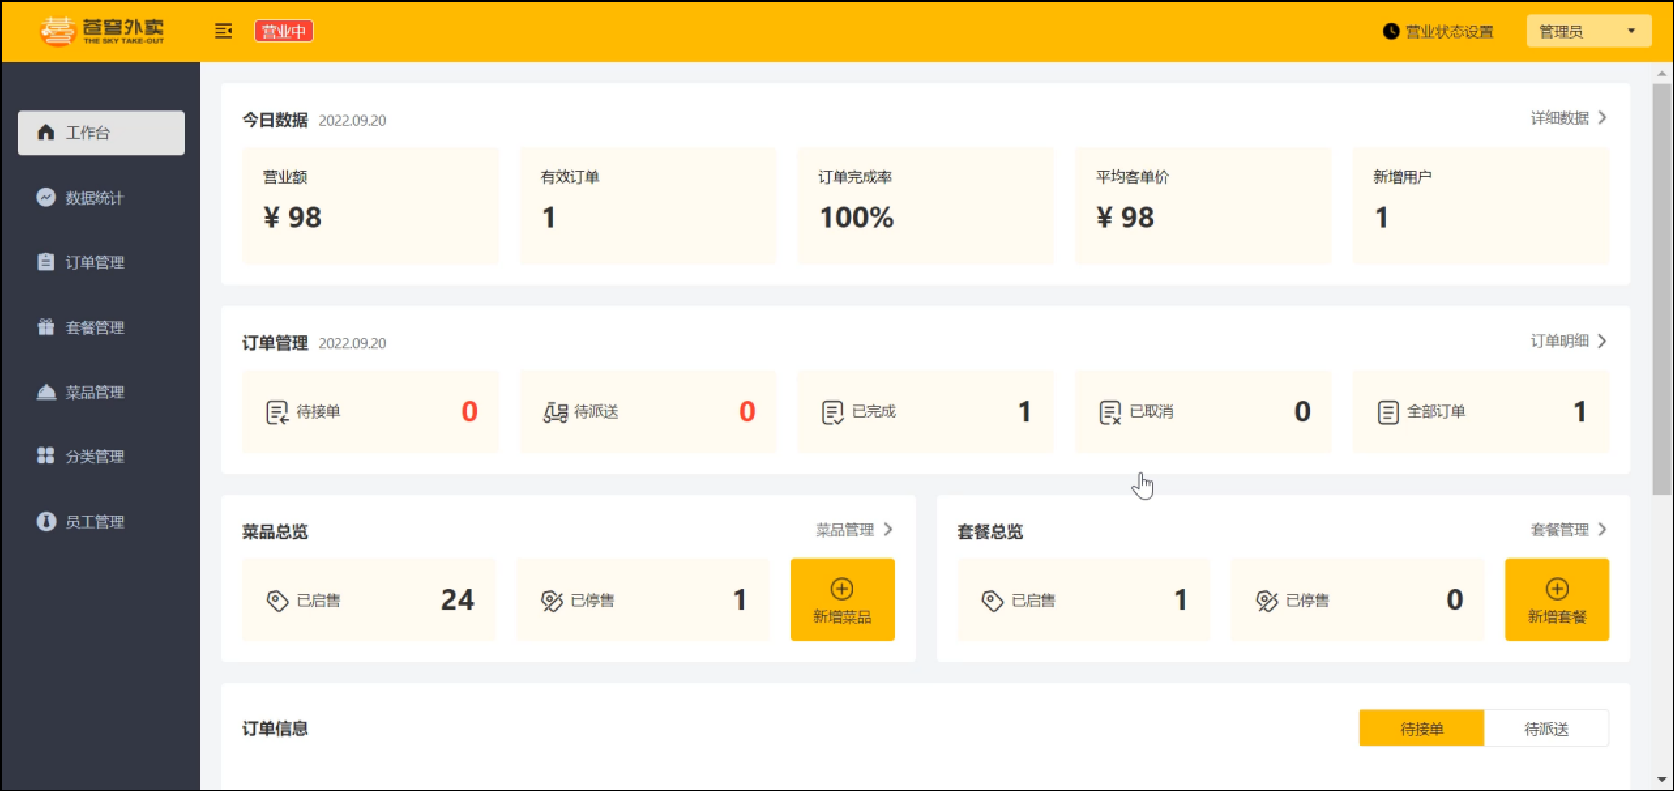  


**数据导出效果图：**

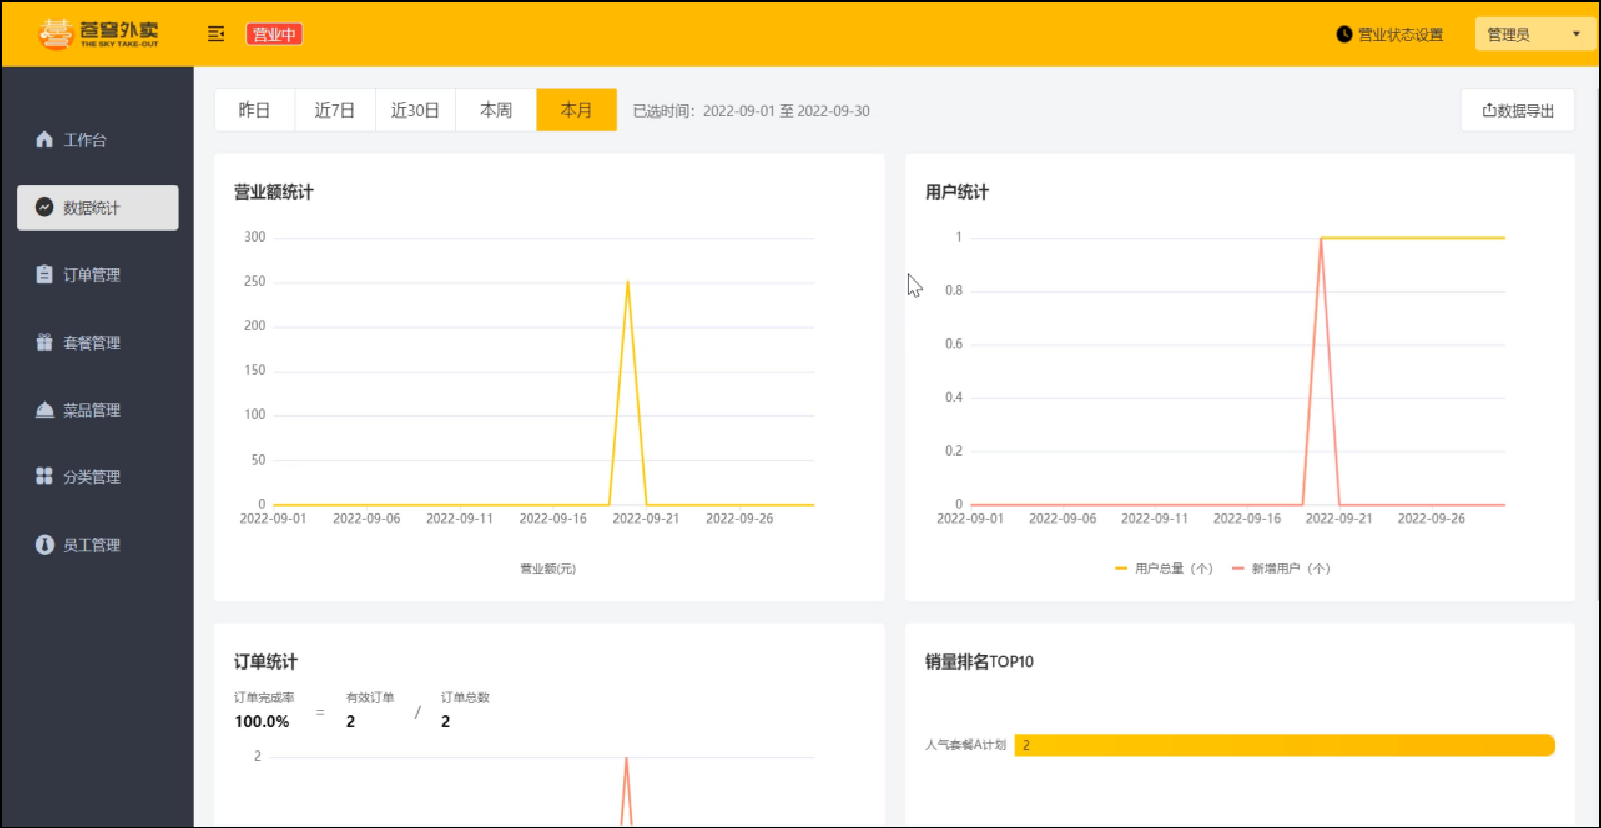   

在数据统计页面点击**数据导出**：生成Excel报表

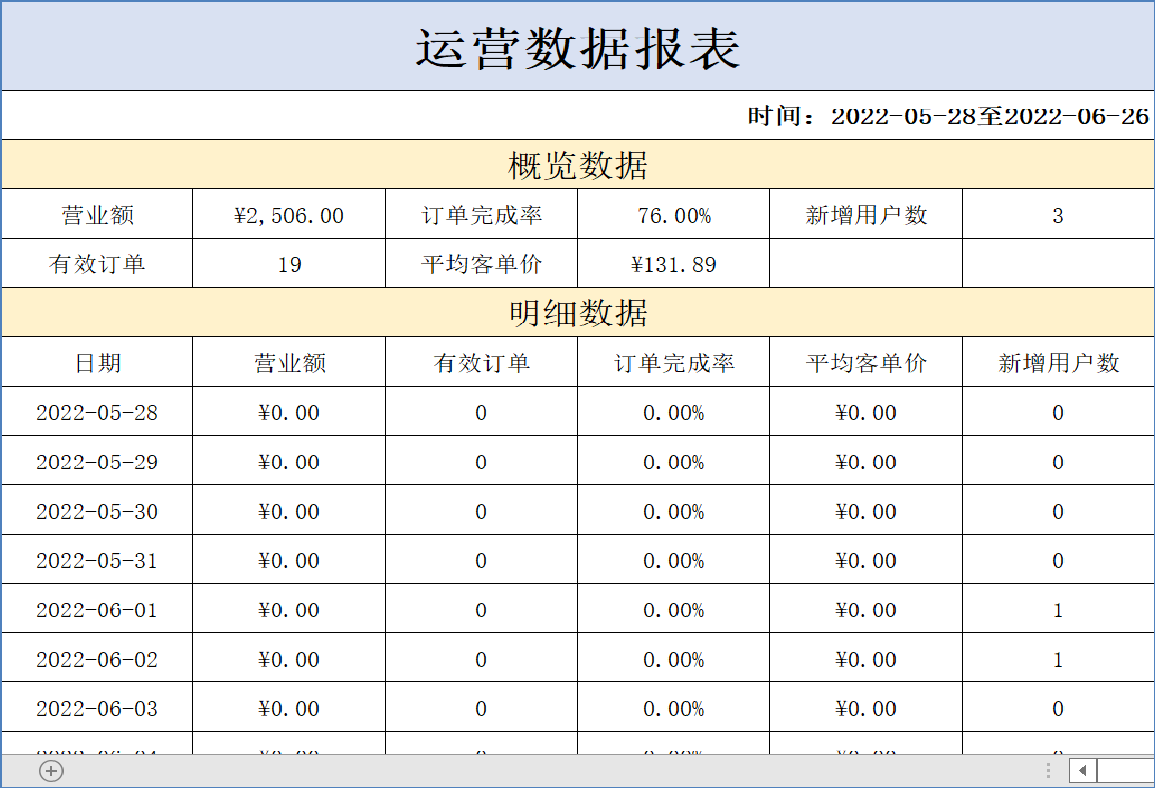


## 1. 工作台

> **PPT对照：** 第5—16页。


### 1.1 需求分析和设计

> **PPT对照：** 第6—12页。

#### 1.1.1 产品原型

工作台是系统运营的数据看板，并提供快捷操作入口，可以有效提高商家的工作效率。

**工作台展示的数据：**

- 今日数据
- 订单管理
- 菜品总览
- 套餐总览
- 订单信息


**原型图：**

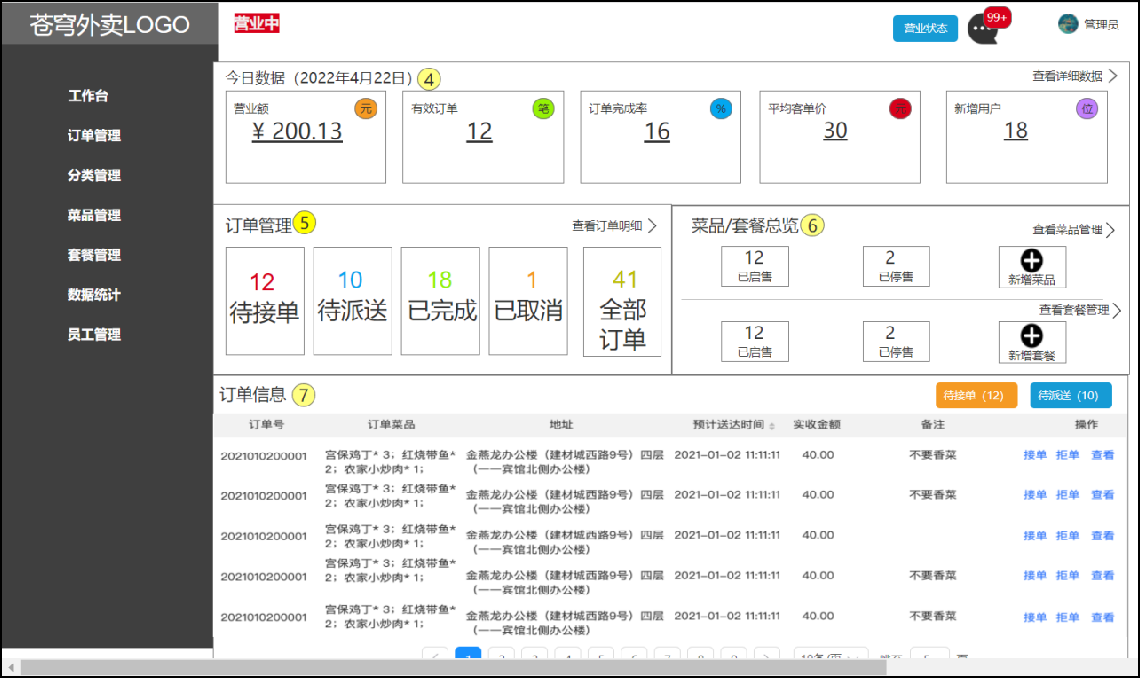 


**名词解释：**

- 营业额：已完成订单的总金额
- 有效订单：已完成订单的数量
- 订单完成率：有效订单数 / 总订单数 * 100%
- 平均客单价：营业额 / 有效订单数
- 新增用户：新增用户的数量


#### 1.1.2 接口设计

通过上述原型图分析，共包含6个接口。

**接口设计：**

- 今日数据接口
- 订单管理接口
- 菜品总览接口
- 套餐总览接口
- 订单搜索（已完成）
- 各个状态的订单数量统计（已完成）


**1). 今日数据的接口设计**

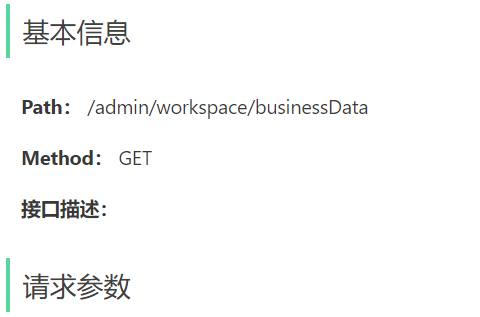 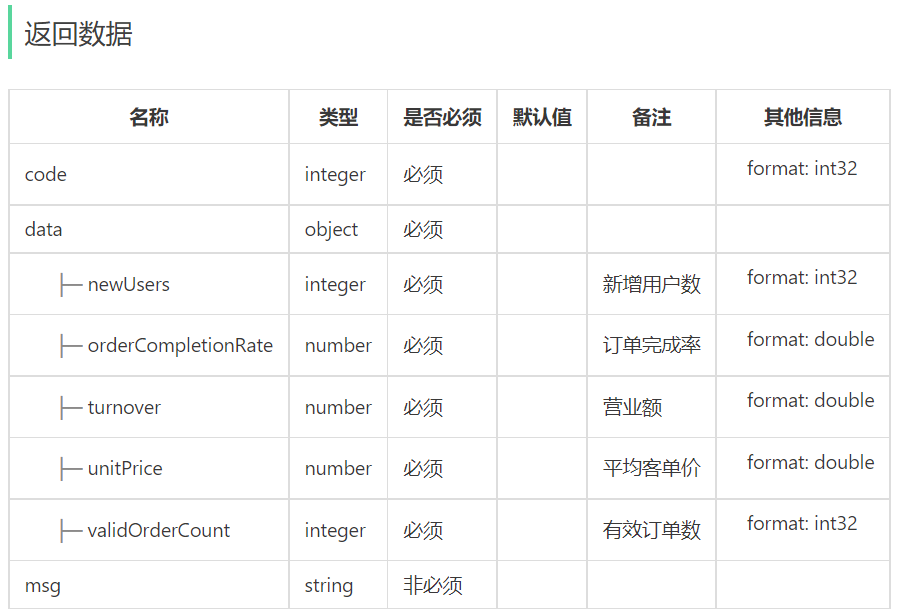

**2). 订单管理的接口设计**

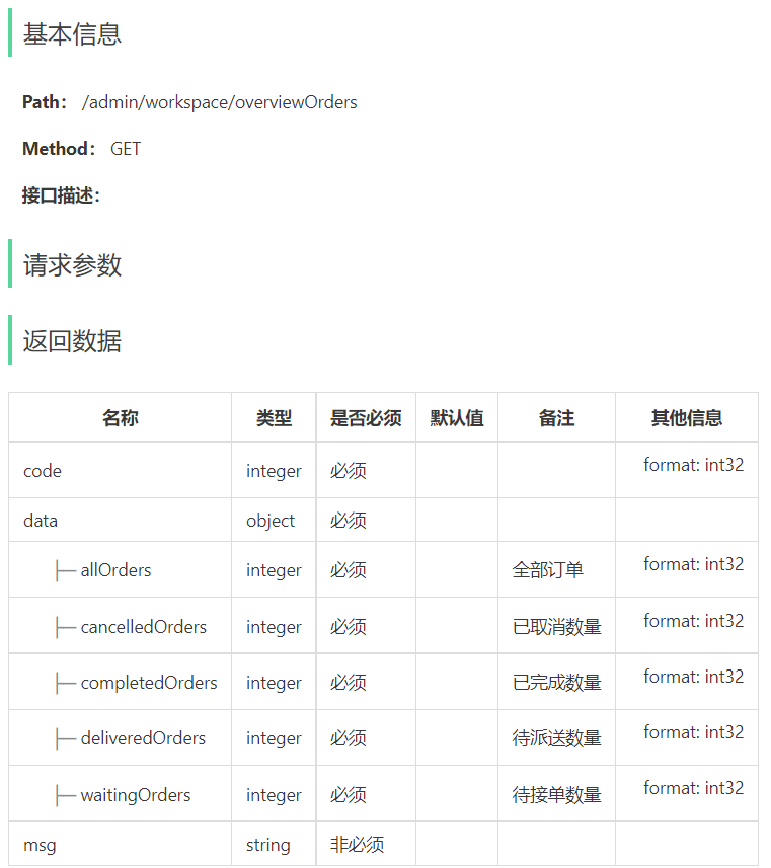 


**3). 菜品总览的接口设计**

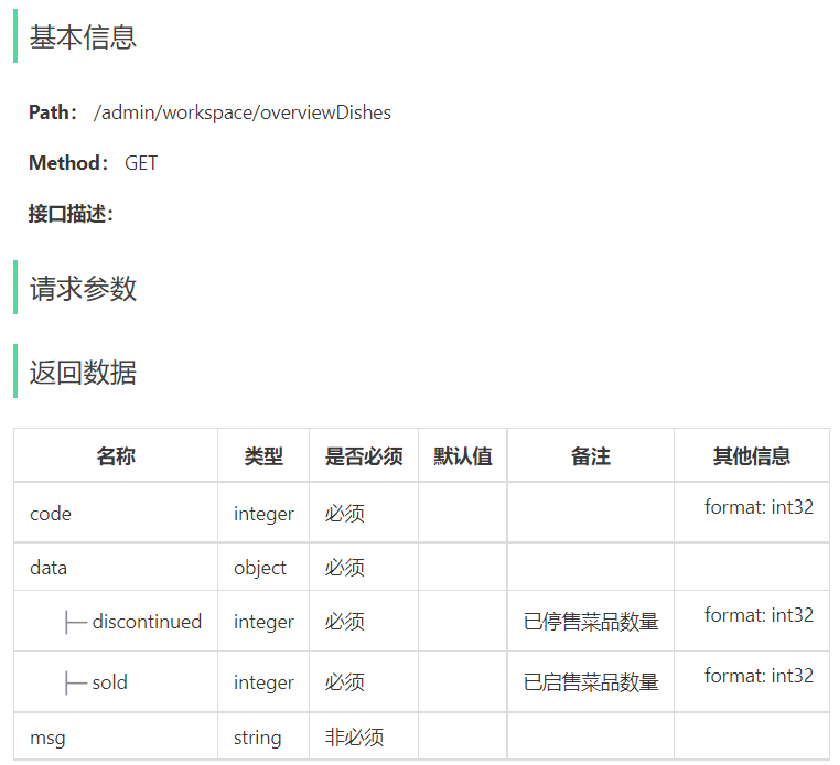 


**4). 套餐总览的接口设计**

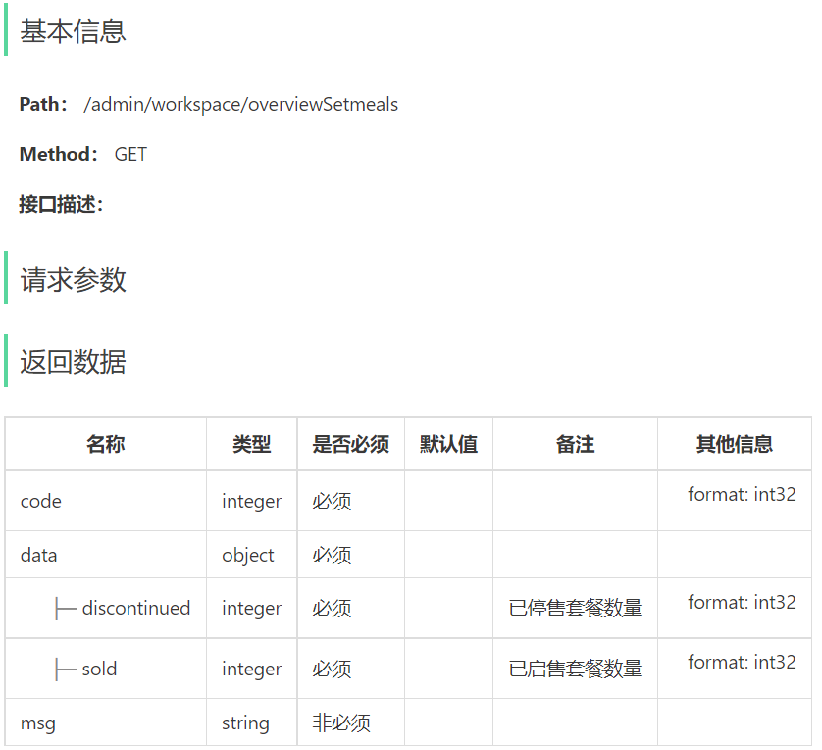


### 工作台指标口径与时间边界（补充）

工作台展示的是当前门店的运营摘要，不是任意时间范围报表。营业额和有效订单只计已完成订单；总订单数包含当天创建的全部订单；订单完成率为有效订单数除以总订单数；平均客单价为营业额除以有效订单数；新增用户按用户创建时间统计。

接口层应一次确定 `begin` 和 `endExclusive`，传给所有查询。不要分别调用 `LocalDateTime.now()` 计算开始和结束，否则跨午夜时可能出现日期不一致。按业务时区处理服务器和数据库时间，页面显示也要使用相同规则。

订单管理、菜品和套餐总览是不同维度。订单状态计数不能复用启停售状态；“全部订单”要有明确的当天范围，不能因缺少结束条件把未来数据也算进来。


### 1.2 代码导入

> **PPT对照：** 第14页。

直接导入课程资料中的工作台模块功能代码即可：

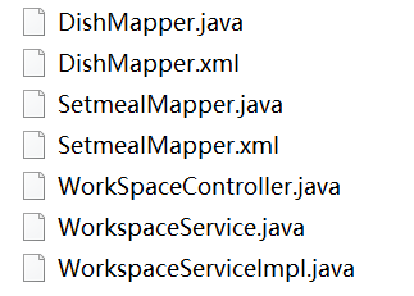 

#### 1.2.1 Controller层

**添加WorkSpaceController.java**

```java
package com.sky.controller.admin;

import com.sky.result.Result;
import com.sky.service.WorkspaceService;
import com.sky.vo.BusinessDataVO;
import com.sky.vo.DishOverViewVO;
import com.sky.vo.OrderOverViewVO;
import com.sky.vo.SetmealOverViewVO;
import io.swagger.annotations.Api;
import io.swagger.annotations.ApiOperation;
import lombok.extern.slf4j.Slf4j;
import org.springframework.beans.factory.annotation.Autowired;
import org.springframework.web.bind.annotation.GetMapping;
import org.springframework.web.bind.annotation.RequestMapping;
import org.springframework.web.bind.annotation.RestController;
import java.time.LocalDateTime;
import java.time.LocalTime;

/**
 * 工作台
 */
@RestController
@RequestMapping("/admin/workspace")
@Slf4j
@Api(tags = "工作台相关接口")
public class WorkSpaceController {

    @Autowired
    private WorkspaceService workspaceService;

    /**
     * 工作台今日数据查询
     * @return
     */
    @GetMapping("/businessData")
    @ApiOperation("工作台今日数据查询")
    public Result<BusinessDataVO> businessData(){
        //获得当天的开始时间
        LocalDateTime begin = LocalDateTime.now().with(LocalTime.MIN);
        //获得当天的结束时间
        LocalDateTime end = LocalDateTime.now().with(LocalTime.MAX);

        BusinessDataVO businessDataVO = workspaceService.getBusinessData(begin, end);
        return Result.success(businessDataVO);
    }

    /**
     * 查询订单管理数据
     * @return
     */
    @GetMapping("/overviewOrders")
    @ApiOperation("查询订单管理数据")
    public Result<OrderOverViewVO> orderOverView(){
        return Result.success(workspaceService.getOrderOverView());
    }

    /**
     * 查询菜品总览
     * @return
     */
    @GetMapping("/overviewDishes")
    @ApiOperation("查询菜品总览")
    public Result<DishOverViewVO> dishOverView(){
        return Result.success(workspaceService.getDishOverView());
    }

    /**
     * 查询套餐总览
     * @return
     */
    @GetMapping("/overviewSetmeals")
    @ApiOperation("查询套餐总览")
    public Result<SetmealOverViewVO> setmealOverView(){
        return Result.success(workspaceService.getSetmealOverView());
    }
}
```


#### 1.2.2 Service层接口

**添加WorkspaceService.java**

```java
package com.sky.service;

import com.sky.vo.BusinessDataVO;
import com.sky.vo.DishOverViewVO;
import com.sky.vo.OrderOverViewVO;
import com.sky.vo.SetmealOverViewVO;
import java.time.LocalDateTime;

public interface WorkspaceService {

    /**
     * 根据时间段统计营业数据
     * @param begin
     * @param end
     * @return
     */
    BusinessDataVO getBusinessData(LocalDateTime begin, LocalDateTime end);

    /**
     * 查询订单管理数据
     * @return
     */
    OrderOverViewVO getOrderOverView();

    /**
     * 查询菜品总览
     * @return
     */
    DishOverViewVO getDishOverView();

    /**
     * 查询套餐总览
     * @return
     */
    SetmealOverViewVO getSetmealOverView();

}
```


#### 1.2.3 Service层实现类

**添加WorkspaceServiceImpl.java**

```java
package com.sky.service.impl;

import com.sky.constant.StatusConstant;
import com.sky.entity.Orders;
import com.sky.mapper.DishMapper;
import com.sky.mapper.OrderMapper;
import com.sky.mapper.SetmealMapper;
import com.sky.mapper.UserMapper;
import com.sky.service.WorkspaceService;
import com.sky.vo.BusinessDataVO;
import com.sky.vo.DishOverViewVO;
import com.sky.vo.OrderOverViewVO;
import com.sky.vo.SetmealOverViewVO;
import lombok.extern.slf4j.Slf4j;
import org.springframework.beans.factory.annotation.Autowired;
import org.springframework.stereotype.Service;
import java.time.LocalDateTime;
import java.time.LocalTime;
import java.util.HashMap;
import java.util.Map;

@Service
@Slf4j
public class WorkspaceServiceImpl implements WorkspaceService {

    @Autowired
    private OrderMapper orderMapper;
    @Autowired
    private UserMapper userMapper;
    @Autowired
    private DishMapper dishMapper;
    @Autowired
    private SetmealMapper setmealMapper;

    /**
     * 根据时间段统计营业数据
     * @param begin
     * @param end
     * @return
     */
    public BusinessDataVO getBusinessData(LocalDateTime begin, LocalDateTime end) {
        /**
         * 营业额：当日已完成订单的总金额
         * 有效订单：当日已完成订单的数量
         * 订单完成率：有效订单数 / 总订单数
         * 平均客单价：营业额 / 有效订单数
         * 新增用户：当日新增用户的数量
         */

        Map map = new HashMap();
        map.put("begin",begin);
        map.put("end",end);

        //查询总订单数
        Integer totalOrderCount = orderMapper.countByMap(map);

        map.put("status", Orders.COMPLETED);
        //营业额
        Double turnover = orderMapper.sumByMap(map);
        turnover = turnover == null? 0.0 : turnover;

        //有效订单数
        Integer validOrderCount = orderMapper.countByMap(map);

        Double unitPrice = 0.0;

        Double orderCompletionRate = 0.0;
        if(totalOrderCount != 0 && validOrderCount != 0){
            //订单完成率
            orderCompletionRate = validOrderCount.doubleValue() / totalOrderCount;
            //平均客单价
            unitPrice = turnover / validOrderCount;
        }

        //新增用户数
        Integer newUsers = userMapper.countByMap(map);

        return BusinessDataVO.builder()
                .turnover(turnover)
                .validOrderCount(validOrderCount)
                .orderCompletionRate(orderCompletionRate)
                .unitPrice(unitPrice)
                .newUsers(newUsers)
                .build();
    }


    /**
     * 查询订单管理数据
     *
     * @return
     */
    public OrderOverViewVO getOrderOverView() {
        Map map = new HashMap();
        map.put("begin", LocalDateTime.now().with(LocalTime.MIN));
        map.put("status", Orders.TO_BE_CONFIRMED);

        //待接单
        Integer waitingOrders = orderMapper.countByMap(map);

        //待派送
        map.put("status", Orders.CONFIRMED);
        Integer deliveredOrders = orderMapper.countByMap(map);

        //已完成
        map.put("status", Orders.COMPLETED);
        Integer completedOrders = orderMapper.countByMap(map);

        //已取消
        map.put("status", Orders.CANCELLED);
        Integer cancelledOrders = orderMapper.countByMap(map);

        //全部订单
        map.put("status", null);
        Integer allOrders = orderMapper.countByMap(map);

        return OrderOverViewVO.builder()
                .waitingOrders(waitingOrders)
                .deliveredOrders(deliveredOrders)
                .completedOrders(completedOrders)
                .cancelledOrders(cancelledOrders)
                .allOrders(allOrders)
                .build();
    }

    /**
     * 查询菜品总览
     *
     * @return
     */
    public DishOverViewVO getDishOverView() {
        Map map = new HashMap();
        map.put("status", StatusConstant.ENABLE);
        Integer sold = dishMapper.countByMap(map);

        map.put("status", StatusConstant.DISABLE);
        Integer discontinued = dishMapper.countByMap(map);

        return DishOverViewVO.builder()
                .sold(sold)
                .discontinued(discontinued)
                .build();
    }

    /**
     * 查询套餐总览
     *
     * @return
     */
    public SetmealOverViewVO getSetmealOverView() {
        Map map = new HashMap();
        map.put("status", StatusConstant.ENABLE);
        Integer sold = setmealMapper.countByMap(map);

        map.put("status", StatusConstant.DISABLE);
        Integer discontinued = setmealMapper.countByMap(map);

        return SetmealOverViewVO.builder()
                .sold(sold)
                .discontinued(discontinued)
                .build();
    }
}
```


#### 1.2.4 Mapper层

**在SetmealMapper中添加countByMap方法定义**

```java
	/**
     * 根据条件统计套餐数量
     * @param map
     * @return
     */
    Integer countByMap(Map map);
```

**在SetmealMapper.xml中添加对应SQL实现**

```xml
<select id="countByMap" resultType="java.lang.Integer">
        select count(id) from setmeal
        <where>
            <if test="status != null">
                and status = #{status}
            </if>
            <if test="categoryId != null">
                and category_id = #{categoryId}
            </if>
        </where>
</select>
```


**在DishMapper中添加countByMap方法定义**

```java
	/**
     * 根据条件统计菜品数量
     * @param map
     * @return
     */
    Integer countByMap(Map map);
```

**在DishMapper.xml中添加对应SQL实现**

```xml
<select id="countByMap" resultType="java.lang.Integer">
        select count(id) from dish
        <where>
            <if test="status != null">
                and status = #{status}
            </if>
            <if test="categoryId != null">
                and category_id = #{categoryId}
            </if>
        </where>
</select>
```


### 工作台代码的可维护性、精度与查询问题（补充与勘误）

原 `WorkspaceServiceImpl` 用一个可变 `Map` 依次放入 begin、end、status，再把它传给订单、用户、菜品和套餐 Mapper。按现有 XML，用户、菜品和套餐可能忽略多余字段，但这种隐式复用容易把旧条件带到新查询。建议每次查询创建明确的参数对象或新 Map，并使用泛型。

原代码的营业额和客单价使用 `Double`，金额应使用 `BigDecimal` 或数据库 decimal 的安全映射。计数建议使用 `Long`，并在 VO 中固定前端需要的单位。

订单总览只设置了当天开始时间。如果业务要求“今日订单”，还必须设置下一天开始时间作为上界：

```java
LocalDate today = LocalDate.now(zoneId);
LocalDateTime begin = today.atStartOfDay();
LocalDateTime endExclusive = today.plusDays(1).atStartOfDay();
Map<String, Object> params = new HashMap<>();
params.put("begin", begin);
params.put("endExclusive", endExclusive);
```

工作台每个指标调用一次数据库会形成多次扫描；数据量增长后可按日期和状态做一次聚合，或使用缓存/只读汇总表。至少给订单时间、状态和用户创建时间建立合适索引。

`newUsers` 查询不应依赖订单查询留下的 `status`，应使用独立的用户查询参数。所有 Mapper 参数和 VO 字段应合并已有工程代码，避免导入同名接口覆盖前面章节实现。


### 1.3 功能测试

> **PPT对照：** 第16页。

可以通过如下方式进行测试：

- 通过接口文档测试
- 前后端联调测试

接下来我们使用上述两种方式分别测试。

#### 1.3.1 接口文档测试

**启动服务**，访问http://localhost:8080/doc.html，进入工作台相关接口

**注意：**使用admin用户登录重新获取token，在全局参数设置中添加，防止token失效。

**1). 今日数据查询**

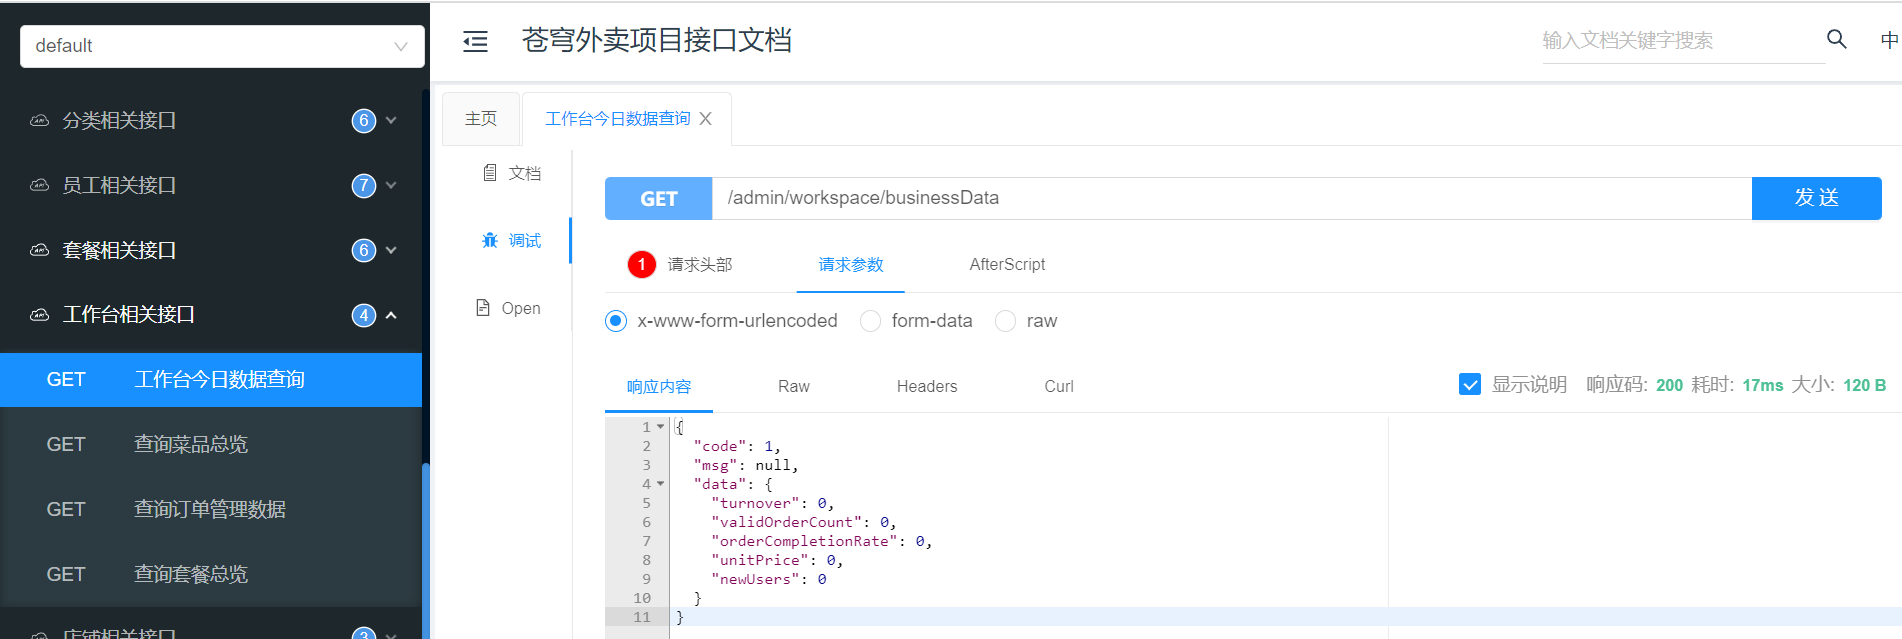 


**2). 菜品总览查询**

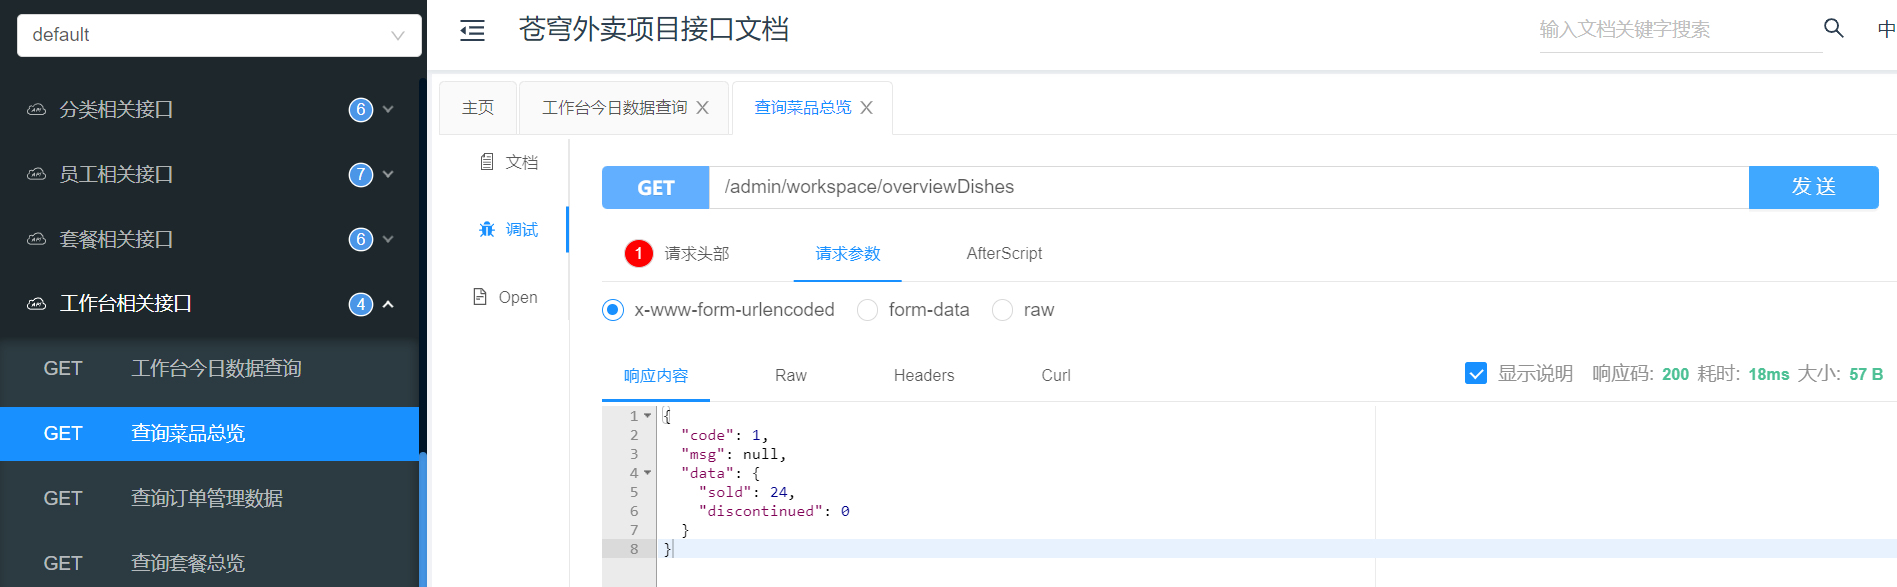 


**3). 订单管理数据查询**

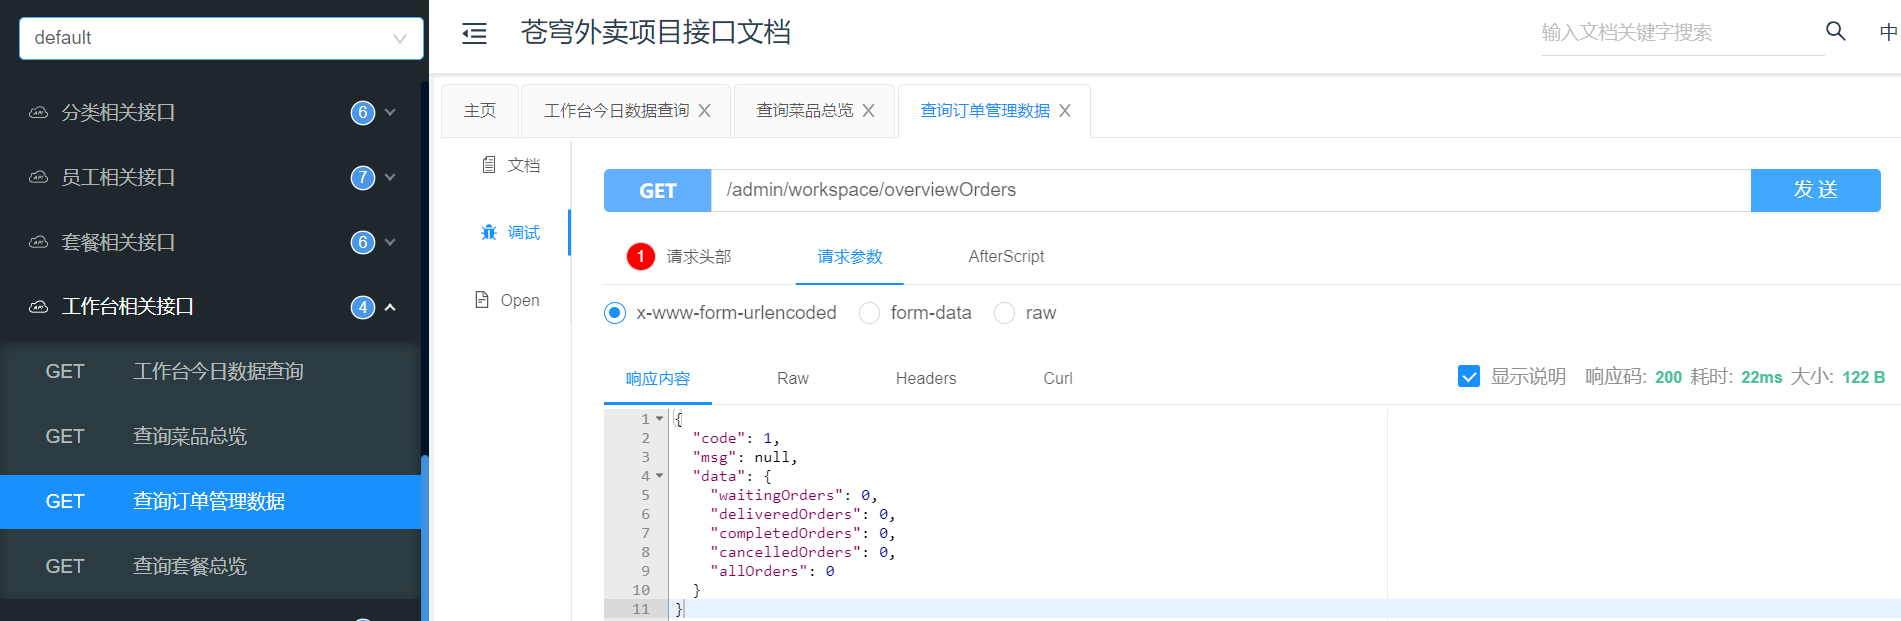 


**4). 套餐总览查询**

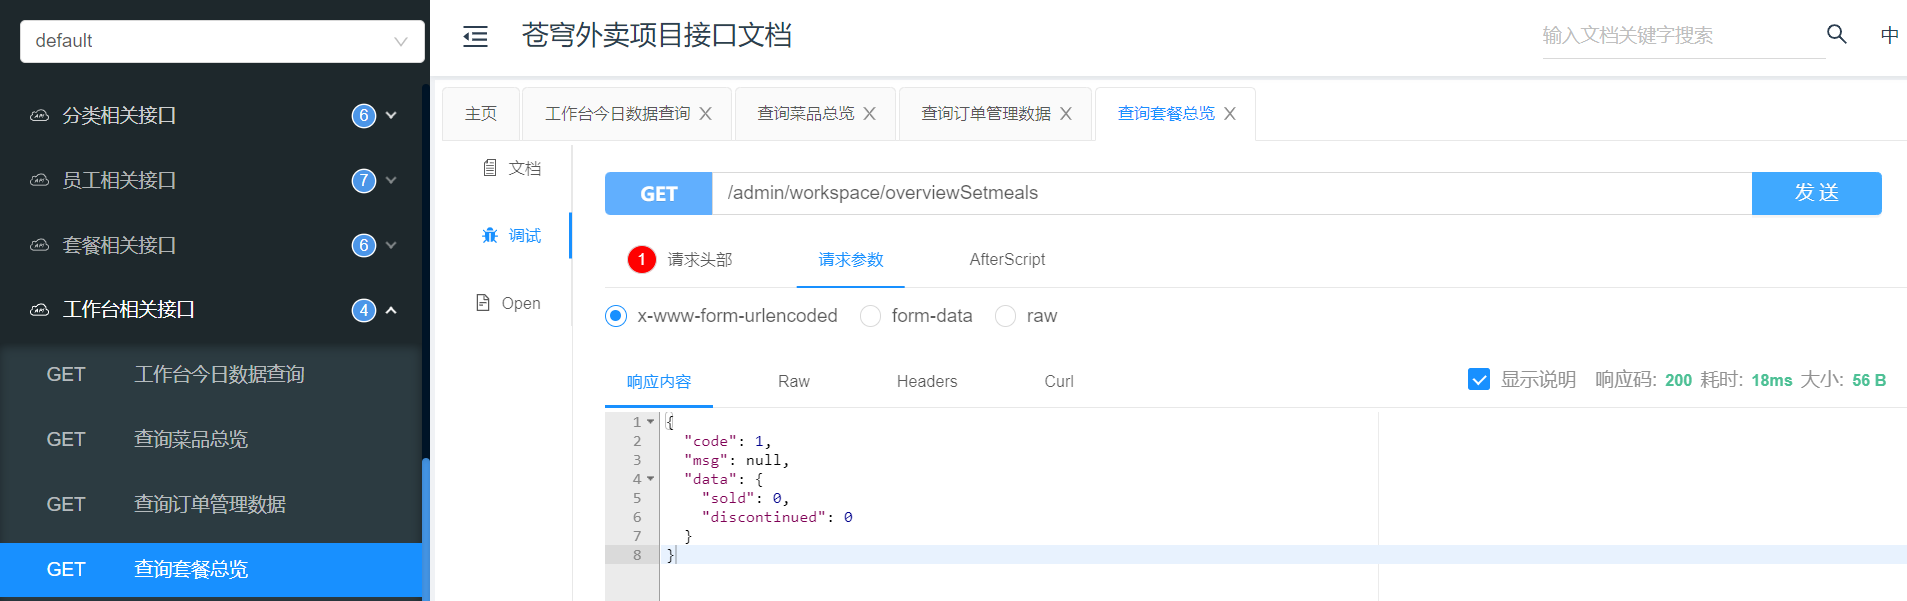 


#### 1.3.2 前后端联调测试

**启动nginx**,访问 http://localhost，进入工作台

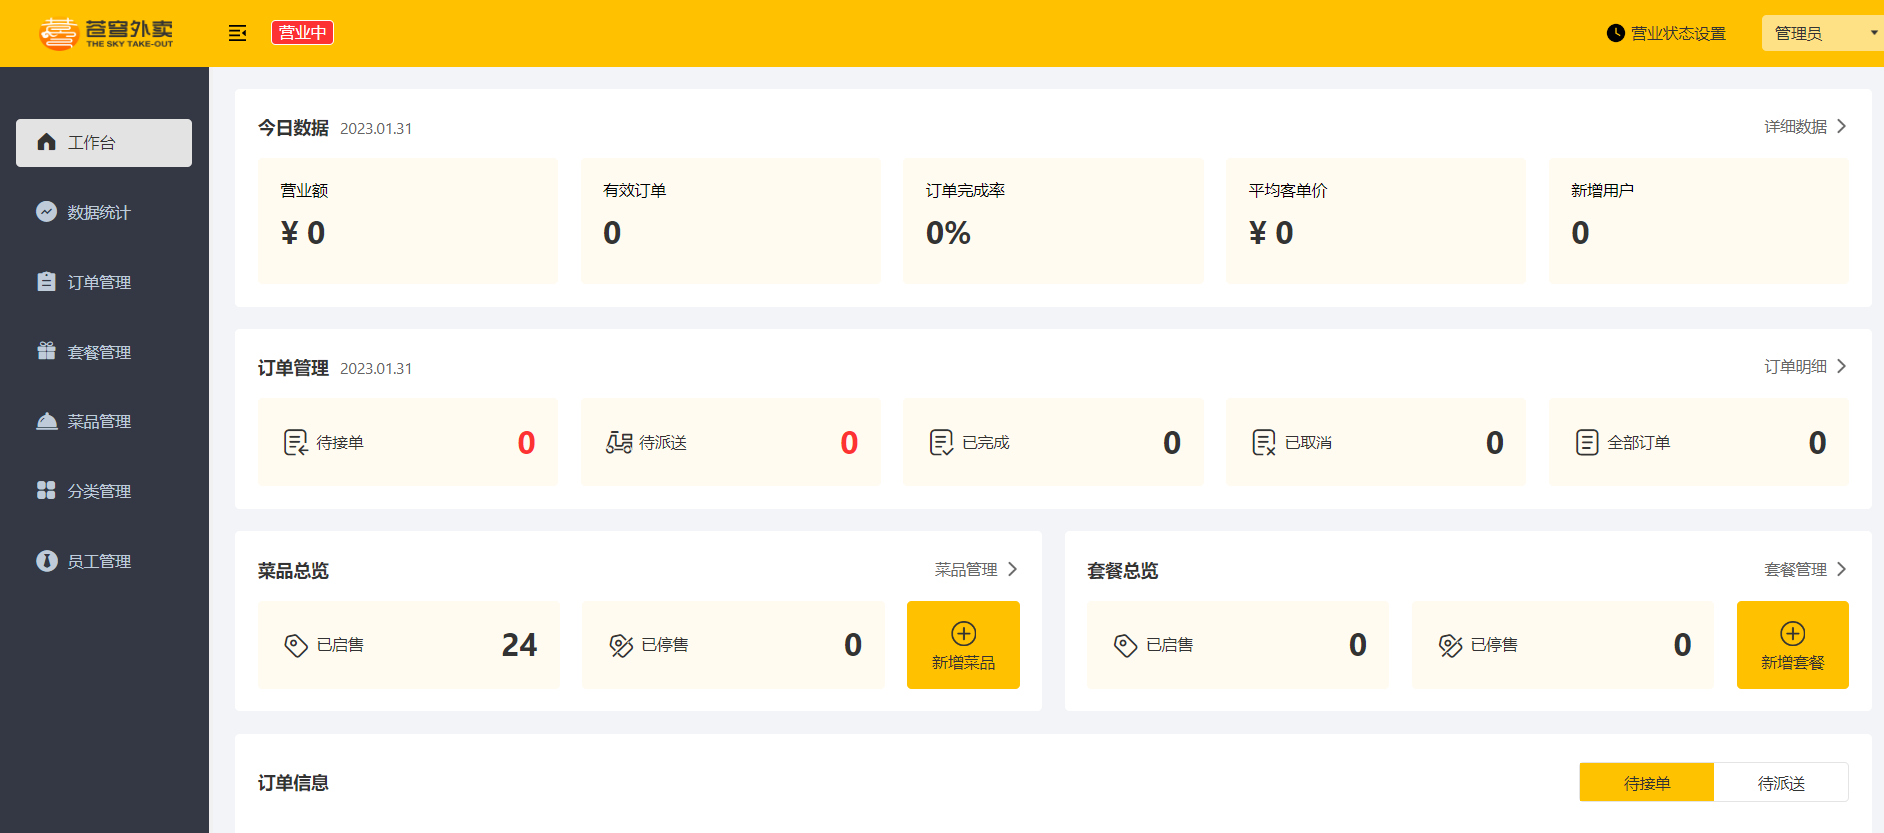 

进入开发者模式，分别查看今日数据、订单管理、菜品总览、套餐总览

**1). 今日数据查询**

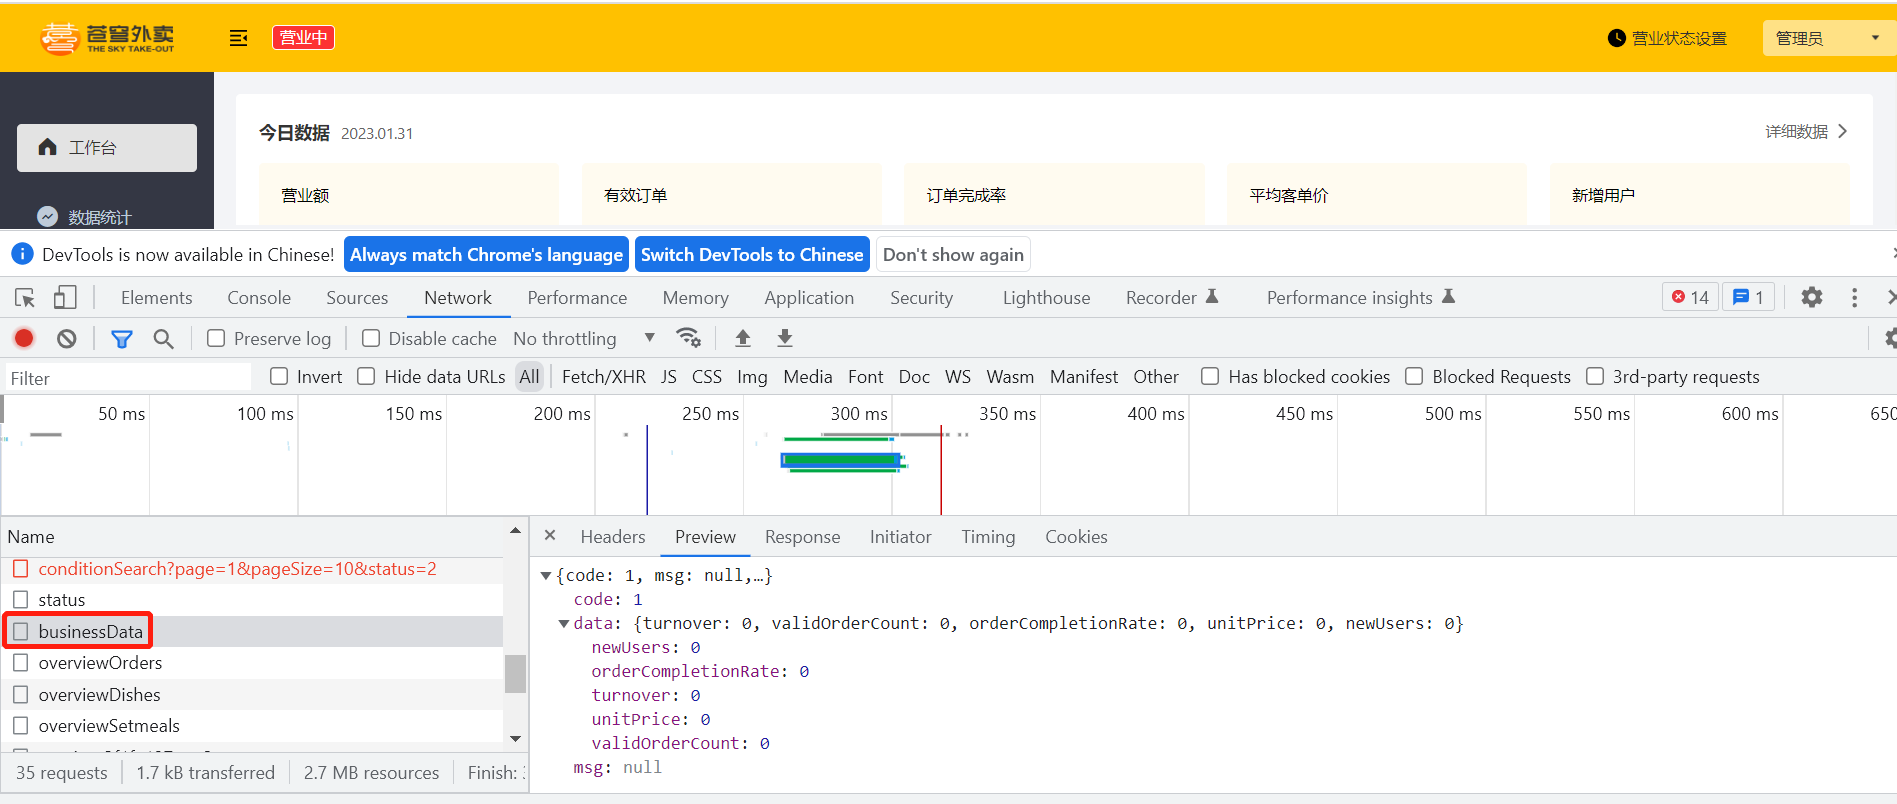 


**2). 订单管理数据查询**

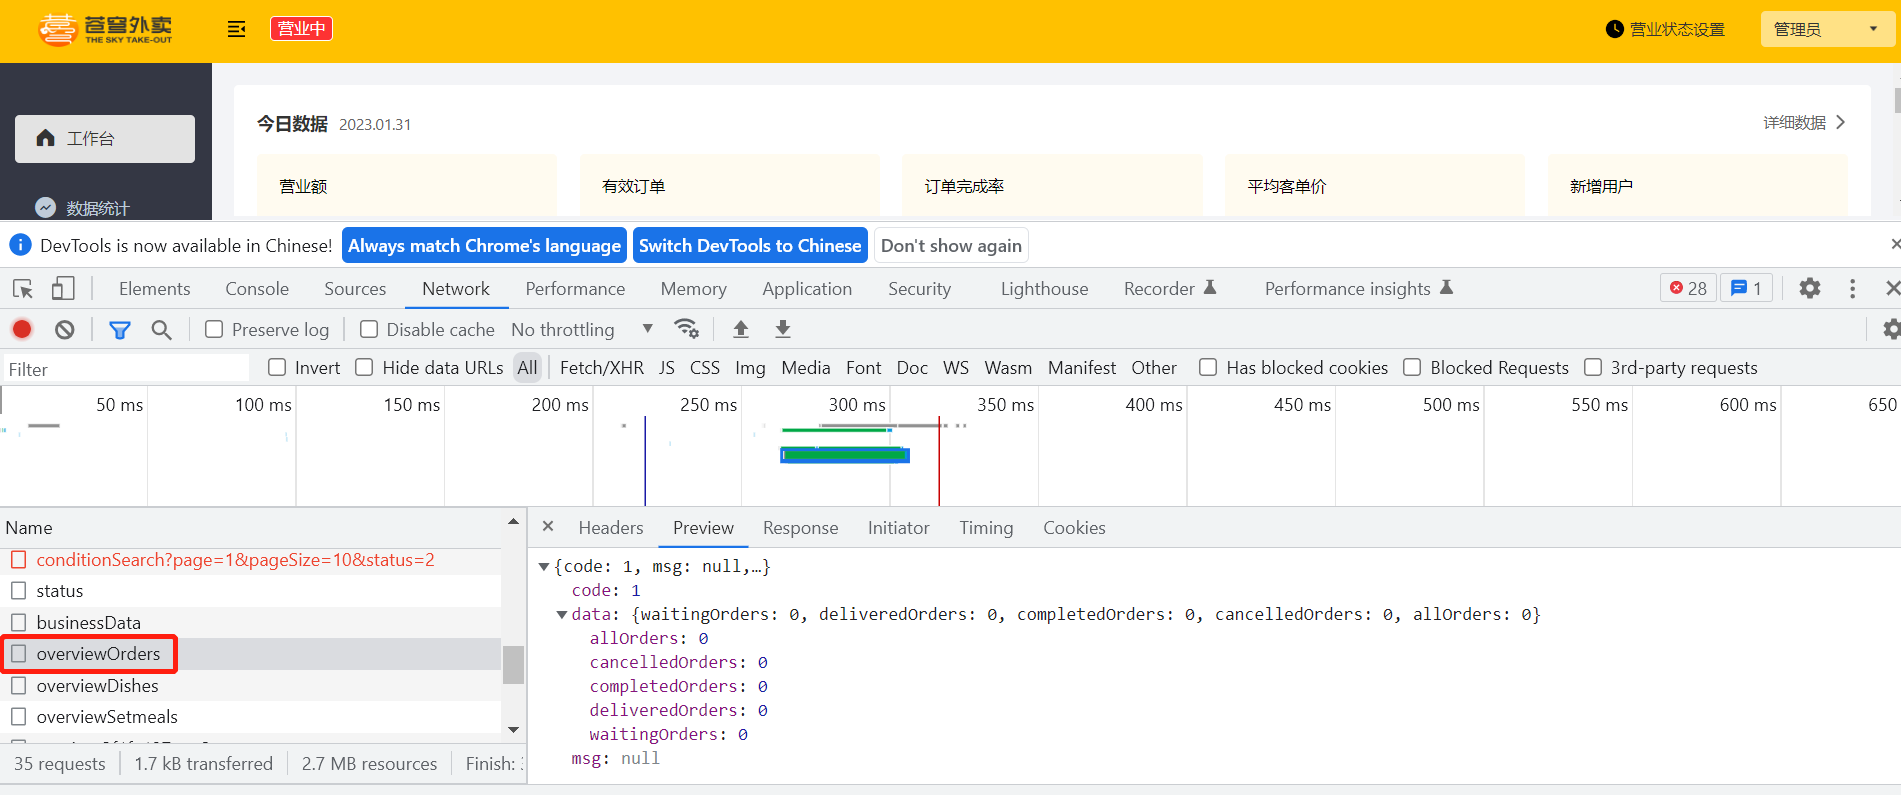 


**3). 菜品总览查询**

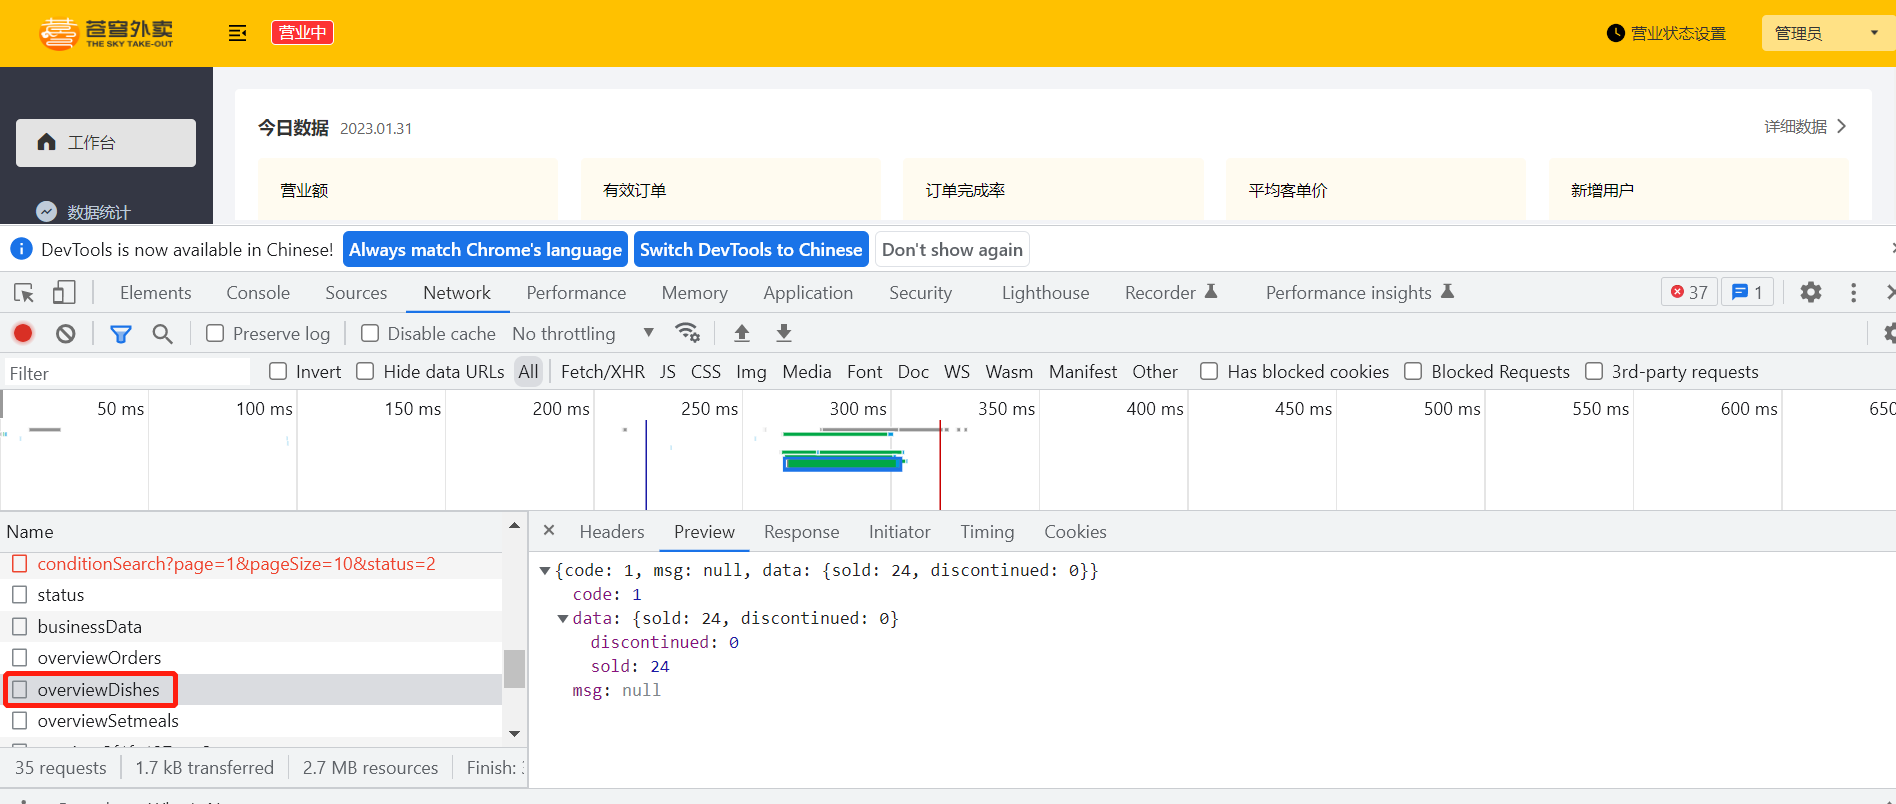 


**4). 套餐总览查询**

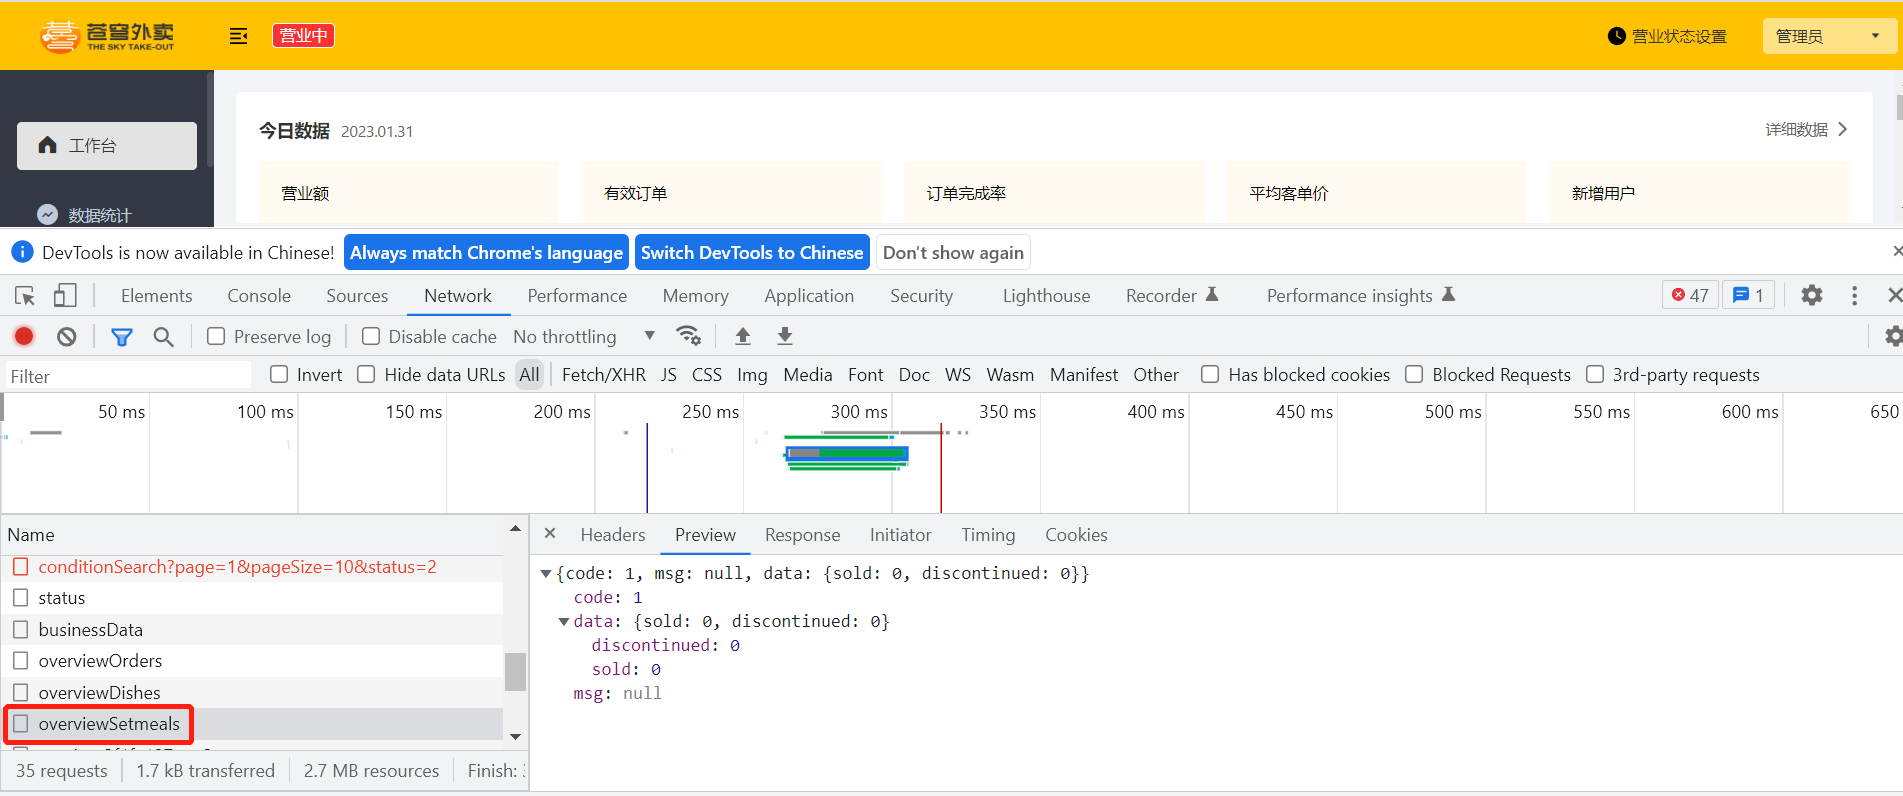


### 工作台验收矩阵（补充）

| 场景 | 预期 |
| --- | --- |
| 今日有已完成订单 | 营业额、有效订单、客单价计算一致 |
| 今日只有待付款或已取消订单 | 有效订单和营业额为0，完成率和客单价不出现 NaN |
| 今日有未来时间订单 | 不计入今日订单总览 |
| 菜品/套餐启售与停售 | 数量分别准确，不混用状态常量 |
| 跨午夜请求 | 所有指标使用同一个门店日期 |
| 无数据 | VO字段返回0或空集合，前端不报错 |
| 非管理员访问 | 被统一鉴权拦截 |

接口文档和前后端联调都要核对响应字段、金额精度、百分比单位和数据库样本，不只看页面卡片是否出现。


### 1.4 代码提交

> **PPT对照：** 课程提交页。

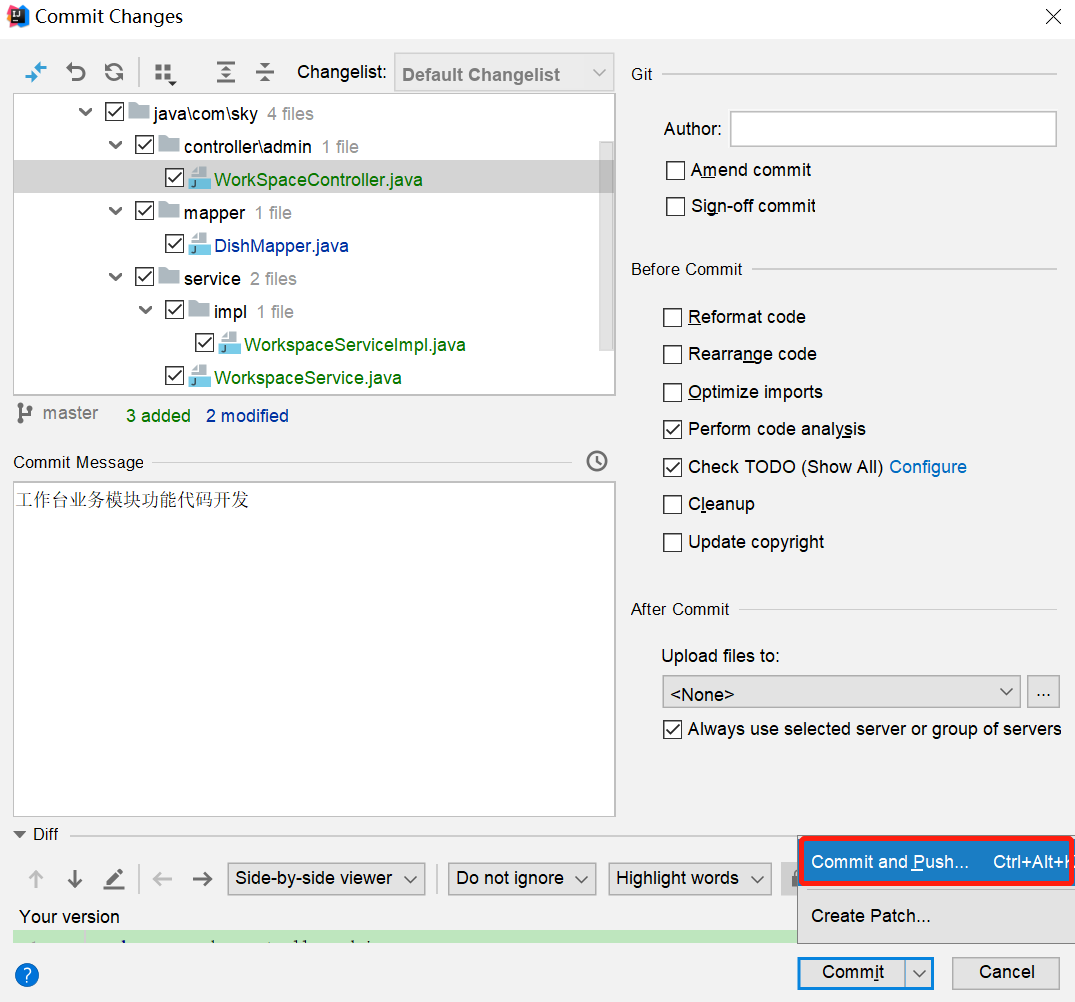 

后续步骤和其它功能代码提交一致，不再赘述。


### 工作台提交前检查（补充）

确认当天上界、时区、金额类型、零分母、独立查询参数、索引和管理员权限已经统一；不要提交带真实 token 或生产数据的截图和日志。


## 2. Apache POI

> **PPT对照：** 第17—25页。


### 2.1 介绍

> **PPT对照：** 第19—21页。

Apache POI 是一个处理Miscrosoft Office各种文件格式的开源项目。简单来说就是，我们可以使用 POI 在 Java 程序中对Miscrosoft Office各种文件进行读写操作。
一般情况下，POI 都是用于操作 Excel 文件。

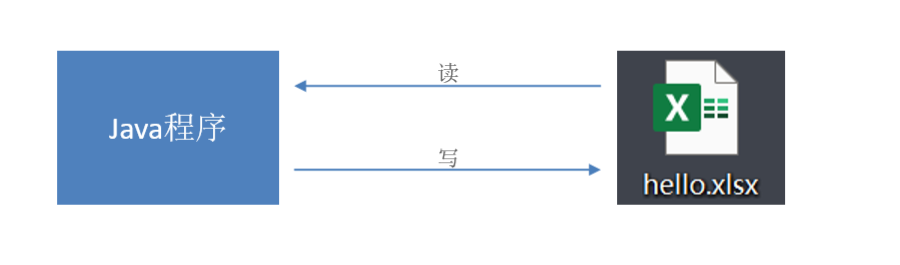 

**Apache POI 的应用场景：**

- 银行网银系统导出交易明细

  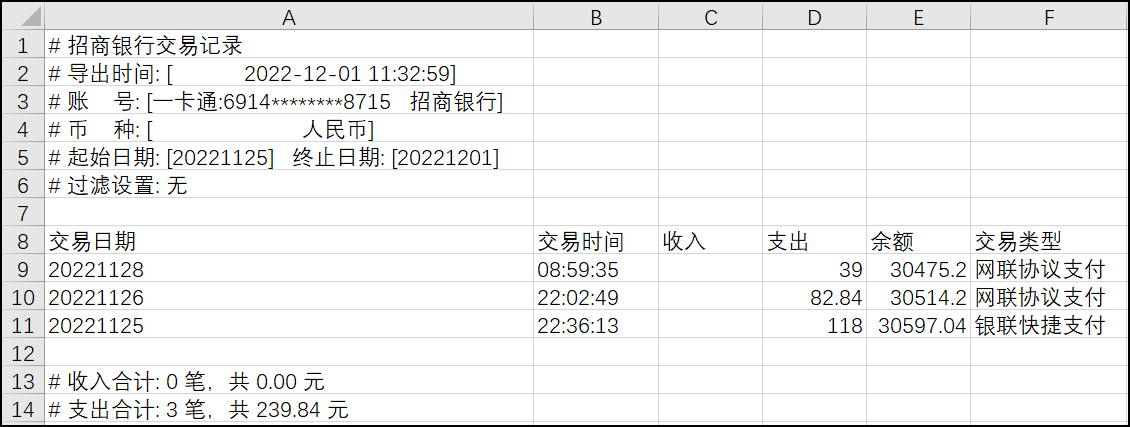 

- 各种业务系统导出Excel报表

  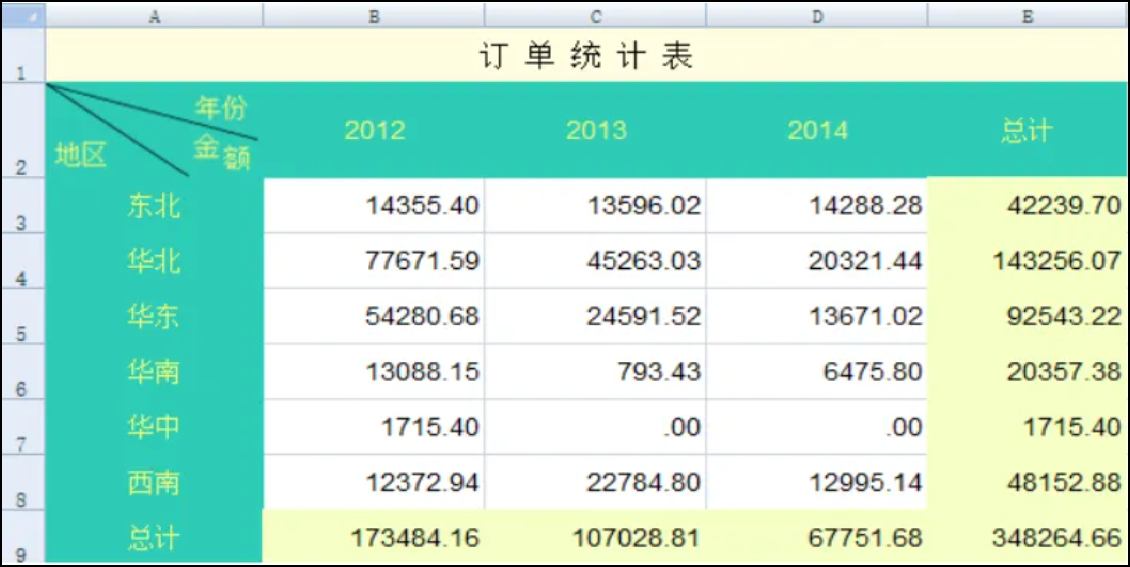 

- 批量导入业务数据

  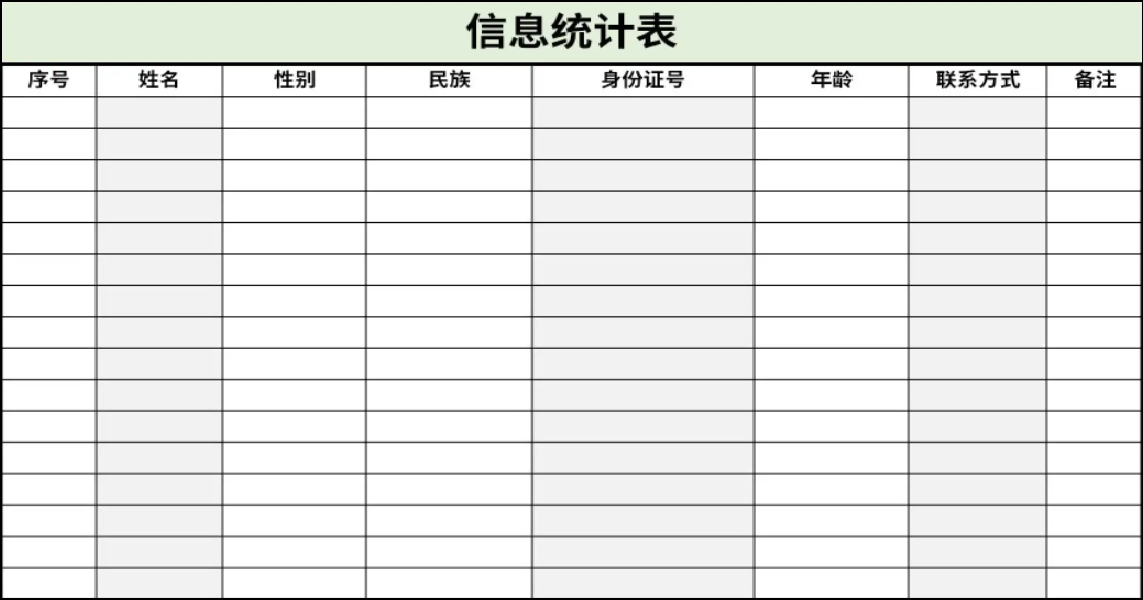


### POI 文件格式与资源管理（补充）

`.xls` 与 `.xlsx` 对应的 POI 工作簿类型不同；本章使用 `XSSFWorkbook` 处理 OOXML 的 `.xlsx`。大量行导出可以考虑 `SXSSFWorkbook` 流式写入，避免把整个工作簿长期保存在堆内存中。

工作簿、输入流和输出流都属于资源，应使用 try-with-resources。Excel 单元格可能是字符串、数字、日期、公式、布尔或空值，读取时不能对所有单元格无条件调用 `getStringCellValue()`。需要导入数据时应使用 `DataFormatter`、公式策略和字段校验。


### 2.2 入门案例

> **PPT对照：** 第23—25页。

Apache POI既可以将数据写入Excel文件，也可以读取Excel文件中的数据，接下来分别进行实现。

**Apache POI的maven坐标：**(项目中已导入)

```xml
<dependency>
    <groupId>org.apache.poi</groupId>
    <artifactId>poi</artifactId>
    <version>3.16</version>
</dependency>
<dependency>
    <groupId>org.apache.poi</groupId>
    <artifactId>poi-ooxml</artifactId>
    <version>3.16</version>
</dependency>
```


#### 2.2.1 将数据写入Excel文件

**1). 代码开发**

```java
package com.sky.test;

import org.apache.poi.xssf.usermodel.XSSFCell;
import org.apache.poi.xssf.usermodel.XSSFRow;
import org.apache.poi.xssf.usermodel.XSSFSheet;
import org.apache.poi.xssf.usermodel.XSSFWorkbook;
import java.io.File;
import java.io.FileInputStream;
import java.io.FileOutputStream;

public class POITest {

    /**
     * 基于POI向Excel文件写入数据
     * @throws Exception
     */
    public static void write() throws Exception{
        //在内存中创建一个Excel文件对象
        XSSFWorkbook excel = new XSSFWorkbook();
        //创建Sheet页
        XSSFSheet sheet = excel.createSheet("itcast");

        //在Sheet页中创建行，0表示第1行
        XSSFRow row1 = sheet.createRow(0);
        //创建单元格并在单元格中设置值，单元格编号也是从0开始，1表示第2个单元格
        row1.createCell(1).setCellValue("姓名");
        row1.createCell(2).setCellValue("城市");

        XSSFRow row2 = sheet.createRow(1);
        row2.createCell(1).setCellValue("张三");
        row2.createCell(2).setCellValue("北京");

        XSSFRow row3 = sheet.createRow(2);
        row3.createCell(1).setCellValue("李四");
        row3.createCell(2).setCellValue("上海");

        FileOutputStream out = new FileOutputStream(new File("D:\\itcast.xlsx"));
        //通过输出流将内存中的Excel文件写入到磁盘上
        excel.write(out);

        //关闭资源
        out.flush();
        out.close();
        excel.close();
    }
    public static void main(String[] args) throws Exception {
        write();
    }
}
```

**2). 实现效果**

在D盘中生成itcast.xlsx文件，创建名称为itcast的Sheet页，同时将内容成功写入。

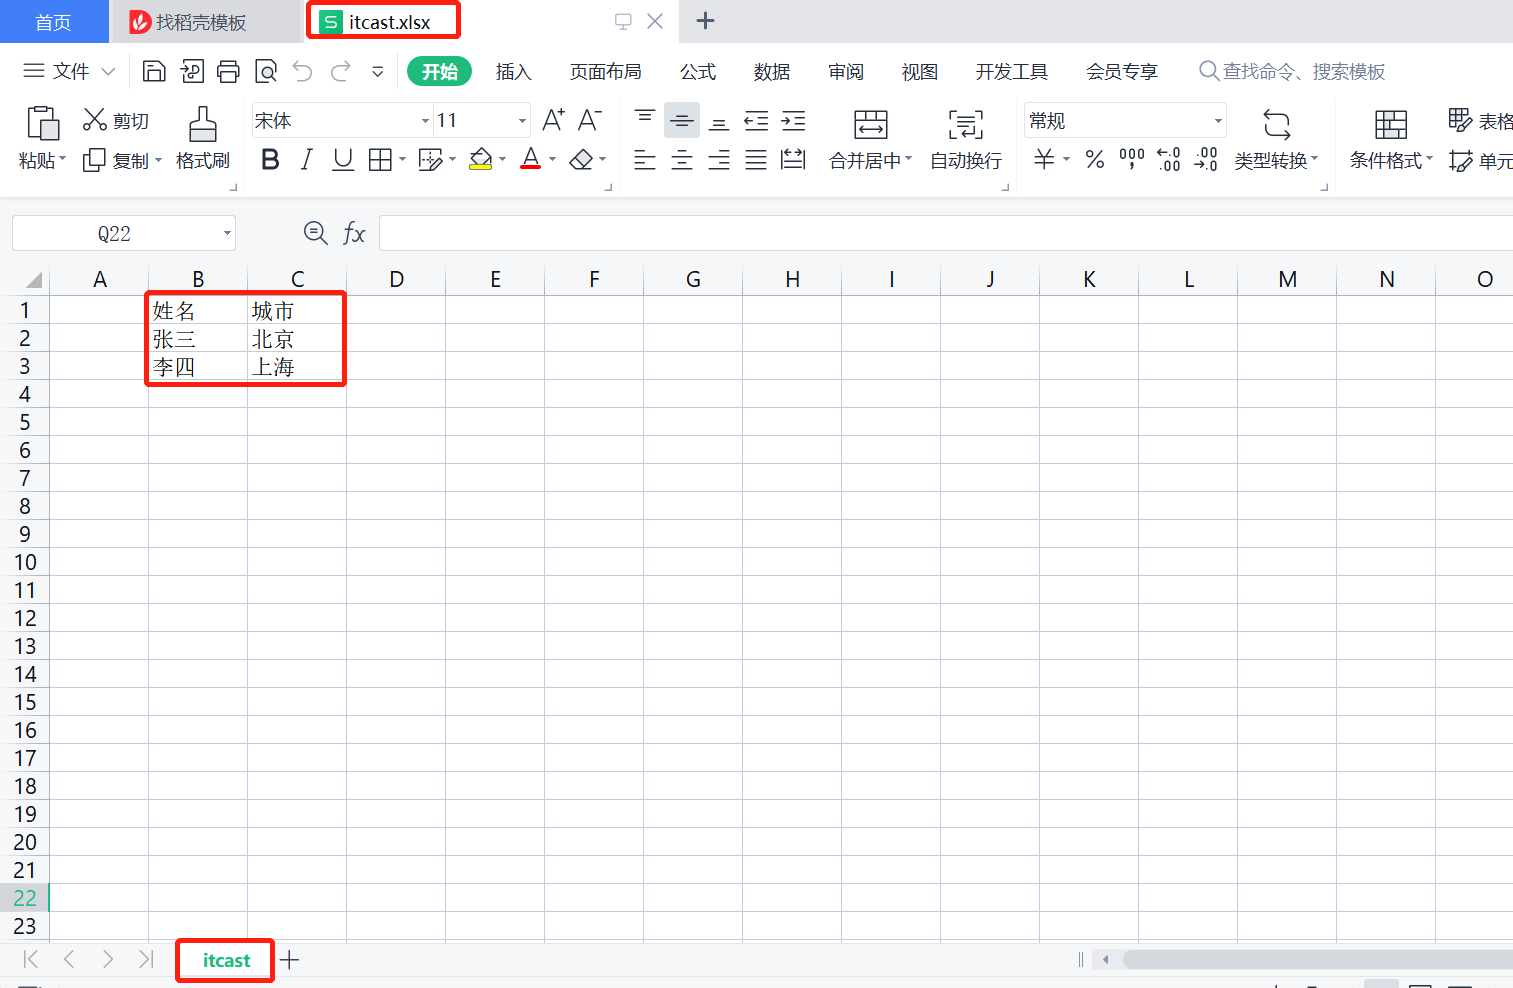 


#### 2.2.2 读取Excel文件中的数据

**1). 代码开发**

```java
package com.sky.test;

import org.apache.poi.xssf.usermodel.XSSFCell;
import org.apache.poi.xssf.usermodel.XSSFRow;
import org.apache.poi.xssf.usermodel.XSSFSheet;
import org.apache.poi.xssf.usermodel.XSSFWorkbook;
import java.io.File;
import java.io.FileInputStream;
import java.io.FileOutputStream;

public class POITest {
    /**
     * 基于POI读取Excel文件
     * @throws Exception
     */
    public static void read() throws Exception{
        FileInputStream in = new FileInputStream(new File("D:\\itcast.xlsx"));
        //通过输入流读取指定的Excel文件
        XSSFWorkbook excel = new XSSFWorkbook(in);
        //获取Excel文件的第1个Sheet页
        XSSFSheet sheet = excel.getSheetAt(0);

        //获取Sheet页中的最后一行的行号
        int lastRowNum = sheet.getLastRowNum();

        for (int i = 0; i <= lastRowNum; i++) {
            //获取Sheet页中的行
            XSSFRow titleRow = sheet.getRow(i);
            //获取行的第2个单元格
            XSSFCell cell1 = titleRow.getCell(1);
            //获取单元格中的文本内容
            String cellValue1 = cell1.getStringCellValue();
            //获取行的第3个单元格
            XSSFCell cell2 = titleRow.getCell(2);
            //获取单元格中的文本内容
            String cellValue2 = cell2.getStringCellValue();

            System.out.println(cellValue1 + " " +cellValue2);
        }

        //关闭资源
        in.close();
        excel.close();
    }

    public static void main(String[] args) throws Exception {
        read();
    }
}

```


**2). 实现效果**

将itcast.xlsx文件中的数据进行读取

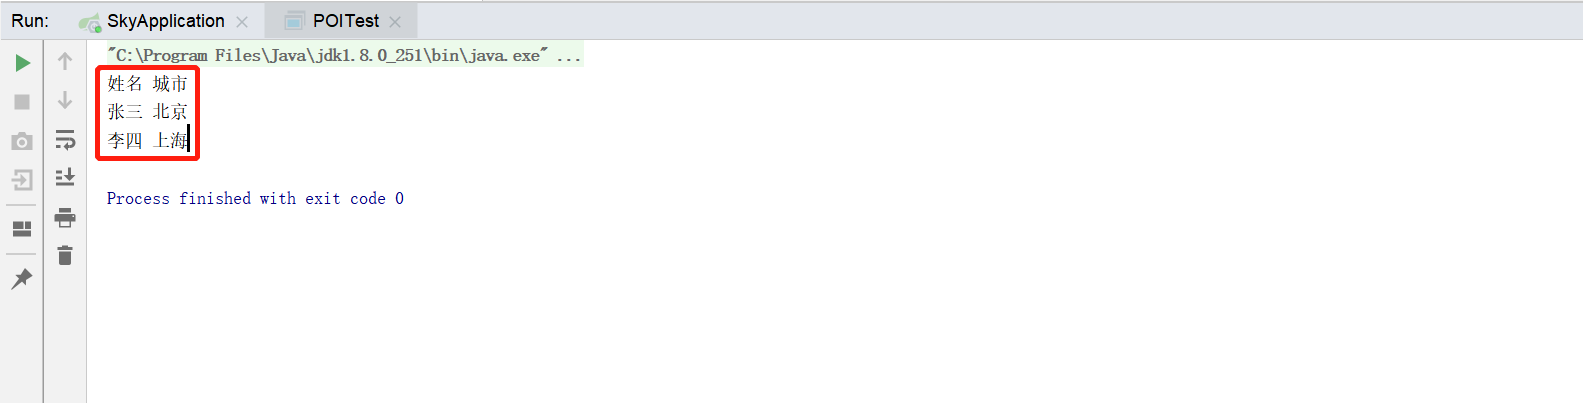


### POI 入门代码的安全改写（补充与勘误）

示例中的 `D:\itcast.xlsx` 是本地演示路径，服务端不能依赖固定盘符。文件名和路径应来自受控目录或资源，不允许把用户输入直接拼接到文件系统路径。

写文件时使用 try-with-resources 并在最后关闭工作簿：

```java
try (XSSFWorkbook workbook = new XSSFWorkbook();
     FileOutputStream out = new FileOutputStream(targetPath.toFile())) {
    XSSFSheet sheet = workbook.createSheet("itcast");
    sheet.createRow(0).createCell(0).setCellValue("姓名");
    workbook.write(out);
}
```

读取文件时先检查文件大小、格式和行列边界。`getRow(i)` 或 `getCell(j)` 可能返回 null；公式单元格和日期单元格要按业务规则读取。不要把任意上传文件直接交给 POI，生产接口需要限制大小、扩展名和解析耗时。


## 3. 导出运营数据Excel报表

> **PPT对照：** 第26—39页。


### 3.1 需求分析和设计

> **PPT对照：** 第28—30页。

#### 3.1.1 产品原型

在数据统计页面，有一个数据导出的按钮，点击该按钮时，其实就会下载一个文件。这个文件实际上是一个Excel形式的文件，文件中主要包含最近30日运营相关的数据。表格的形式已经固定，主要由概览数据和明细数据两部分组成。真正导出这个报表之后，相对应的数字就会填充在表格中，就可以进行存档。

**原型图：**

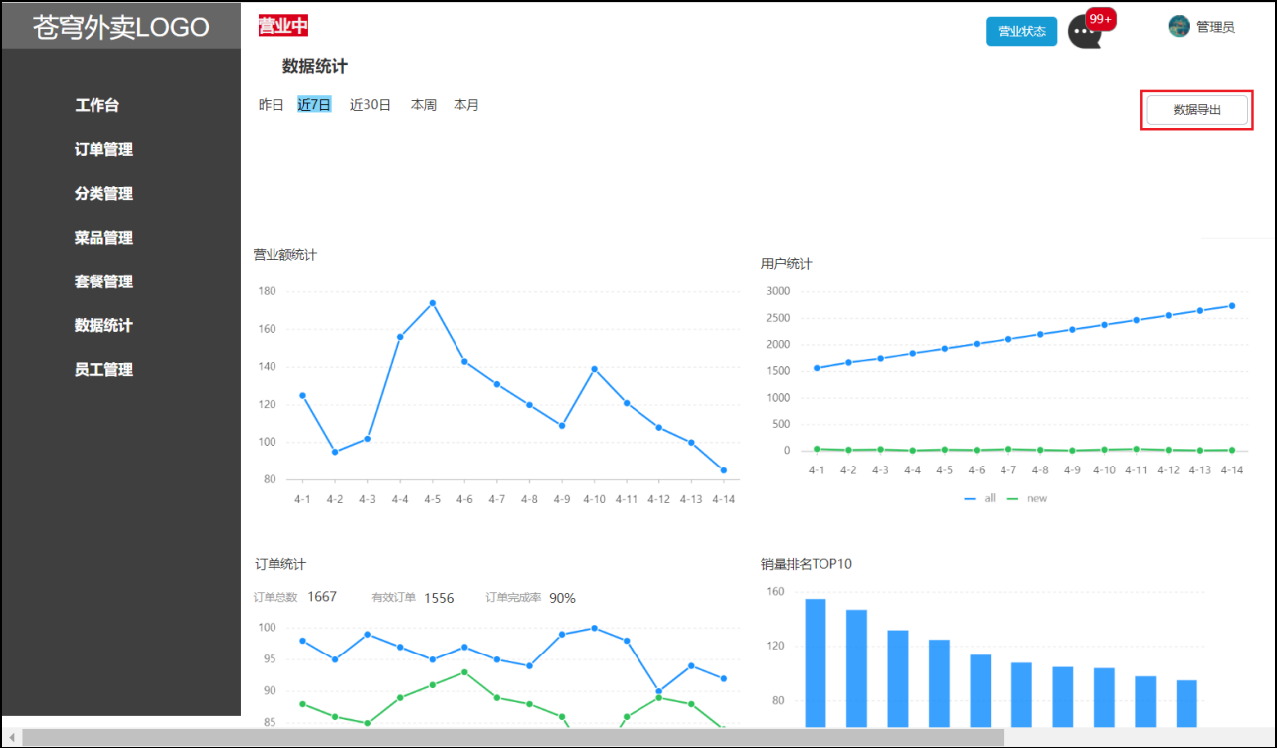 

导出的Excel报表格式：

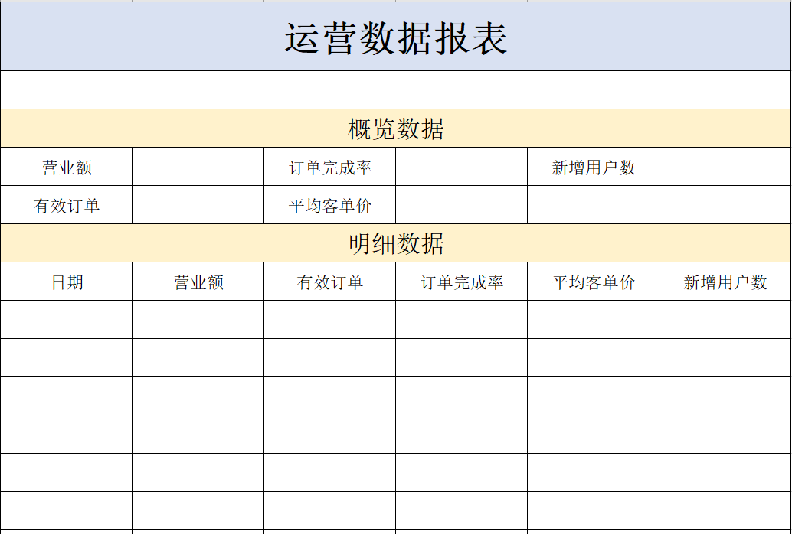  


**业务规则：**

- 导出Excel形式的报表文件
- 导出最近30天的运营数据


#### 3.1.2 接口设计

通过上述原型图设计对应的接口。

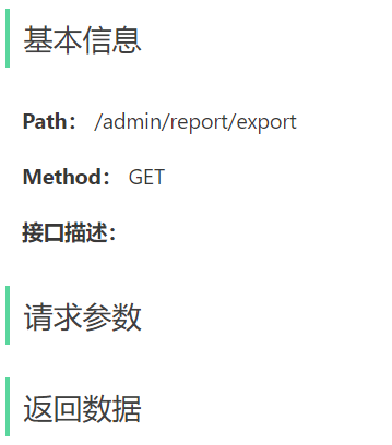 

**注意：**

- 当前接口没有传递参数，因为导出的是最近30天的运营数据，后端计算即可，所以不需要任何参数

- 当前接口没有返回数据，因为报表导出功能本质上是文件下载，服务端会通过输出流将Excel文件下载到客户端浏览器


### Excel 导出的范围与下载契约（补充）

导出最近30天需要明确是否包含今天。讲义使用 `now - 30` 到 `now - 1`，即最近30个完整自然日，不包含今天；模板标题、明细行和接口说明必须保持一致。跨时区时以门店日期计算，不以服务器默认时区猜测。

下载接口虽然没有业务 JSON 返回体，但仍要设置正确的 HTTP 响应头：Excel MIME 类型、附件文件名、文件名 UTF-8 编码和缓存策略。响应已经开始写出后不能再返回统一 JSON 错误。

模板是程序资源的一部分，应在启动或首次导出时检查是否存在、Sheet名称和关键单元格位置。模板变化要有版本管理，不能在代码里默默依赖一组无说明的行列编号。


### 3.2 代码开发

> **PPT对照：** 第32—37页。

#### 3.2.1 实现步骤

1). 设计Excel模板文件

2). 查询近30天的运营数据

3). 将查询到的运营数据写入模板文件

4). 通过输出流将Excel文件下载到客户端浏览器

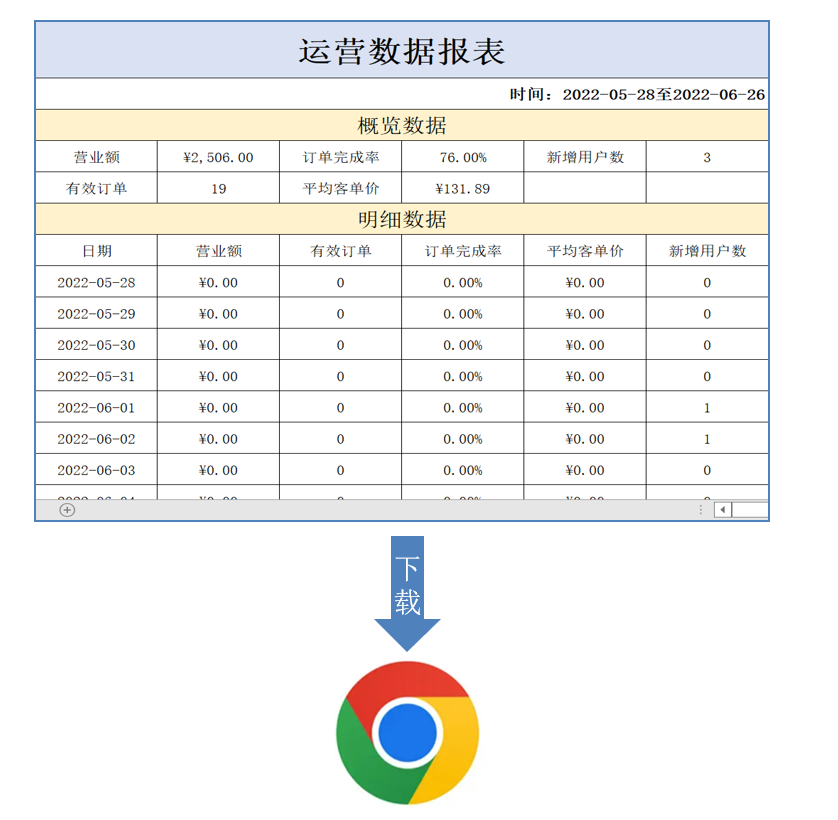 

#### 3.2.2 Controller层

**根据接口定义，在ReportController中创建export方法：**

```java
	/**
     * 导出运营数据报表
     * @param response
     */
    @GetMapping("/export")
    @ApiOperation("导出运营数据报表")
    public void export(HttpServletResponse response){
        reportService.exportBusinessData(response);
    }
```


#### 3.2.3 Service层接口

**在ReportService接口中声明导出运营数据报表的方法：**

```java
	/**
     * 导出近30天的运营数据报表
     * @param response
     **/
    void exportBusinessData(HttpServletResponse response);
```


#### 3.2.4 Service层实现类

**在ReportServiceImpl实现类中实现导出运营数据报表的方法:**

提前将资料中的**运营数据报表模板.xlsx**拷贝到项目的resources/template目录中

```java
    /**导出近30天的运营数据报表
     * @param response
     **/
    public void exportBusinessData(HttpServletResponse response) {
        LocalDate begin = LocalDate.now().minusDays(30);
        LocalDate end = LocalDate.now().minusDays(1);
        //查询概览运营数据，提供给Excel模板文件
        BusinessDataVO businessData = workspaceService.getBusinessData(LocalDateTime.of(begin,LocalTime.MIN), LocalDateTime.of(end, LocalTime.MAX));
        InputStream inputStream = this.getClass().getClassLoader().getResourceAsStream("template/运营数据报表模板.xlsx");
        try {
            //基于提供好的模板文件创建一个新的Excel表格对象
            XSSFWorkbook excel = new XSSFWorkbook(inputStream);
            //获得Excel文件中的一个Sheet页
            XSSFSheet sheet = excel.getSheet("Sheet1");

            sheet.getRow(1).getCell(1).setCellValue(begin + "至" + end);
            //获得第4行
            XSSFRow row = sheet.getRow(3);
            //获取单元格
            row.getCell(2).setCellValue(businessData.getTurnover());
            row.getCell(4).setCellValue(businessData.getOrderCompletionRate());
            row.getCell(6).setCellValue(businessData.getNewUsers());
            row = sheet.getRow(4);
            row.getCell(2).setCellValue(businessData.getValidOrderCount());
            row.getCell(4).setCellValue(businessData.getUnitPrice());
            for (int i = 0; i < 30; i++) {
                LocalDate date = begin.plusDays(i);
               //准备明细数据
                businessData = workspaceService.getBusinessData(LocalDateTime.of(date,LocalTime.MIN), LocalDateTime.of(date, LocalTime.MAX));
                row = sheet.getRow(7 + i);
                row.getCell(1).setCellValue(date.toString());
                row.getCell(2).setCellValue(businessData.getTurnover());
                row.getCell(3).setCellValue(businessData.getValidOrderCount());
                row.getCell(4).setCellValue(businessData.getOrderCompletionRate());
                row.getCell(5).setCellValue(businessData.getUnitPrice());
                row.getCell(6).setCellValue(businessData.getNewUsers());
            }
            //通过输出流将文件下载到客户端浏览器中
            ServletOutputStream out = response.getOutputStream();
            excel.write(out);
            //关闭资源
            out.flush();
            out.close();
            excel.close();

        }catch (IOException e){
            e.printStackTrace();
        }
    }
```


### 导出实现的资源、性能与失败处理（补充与勘误）

原实现先查询30天概览，再循环30次调用 `workspaceService.getBusinessData`，而工作台方法本身会发出多次SQL，导出请求可能产生数百次查询。可一次查询按日聚合所有明细，再映射到模板；如果暂时保留循环，至少限制并发导出、记录耗时并使用索引。

导出服务还应补充以下保护：

- `getResourceAsStream` 返回 null 时立即报配置错误，不要让 `new XSSFWorkbook(null)` 产生难定位的异常；
- 使用 try-with-resources 管理模板输入流、工作簿和响应输出流，记录结构化错误日志；
- 设置 `Content-Type: application/vnd.openxmlformats-officedocument.spreadsheetml.sheet` 和 RFC 5987 文件名；
- 不把用户输入写入公式，防止 Excel 公式注入；文本以字符串写入，金额、日期和百分比按格式写入；
- 大文件使用流式工作簿或异步导出，限制单次导出日期范围和并发量。

导出异常不能只 `e.printStackTrace()` 后返回空响应。接口应在响应尚未提交时返回统一错误；已经提交后记录 request id 并让客户端看到明确的下载失败。

模板中的百分比单元格要确认写入的是 `0.25` 还是 `25`，并由单元格格式决定显示。营业额和客单价的精度要和数据库、工作台接口一致。


### 3.3 功能测试

> **PPT对照：** 第39页。

直接使用前后端联调测试。

**进入数据统计**

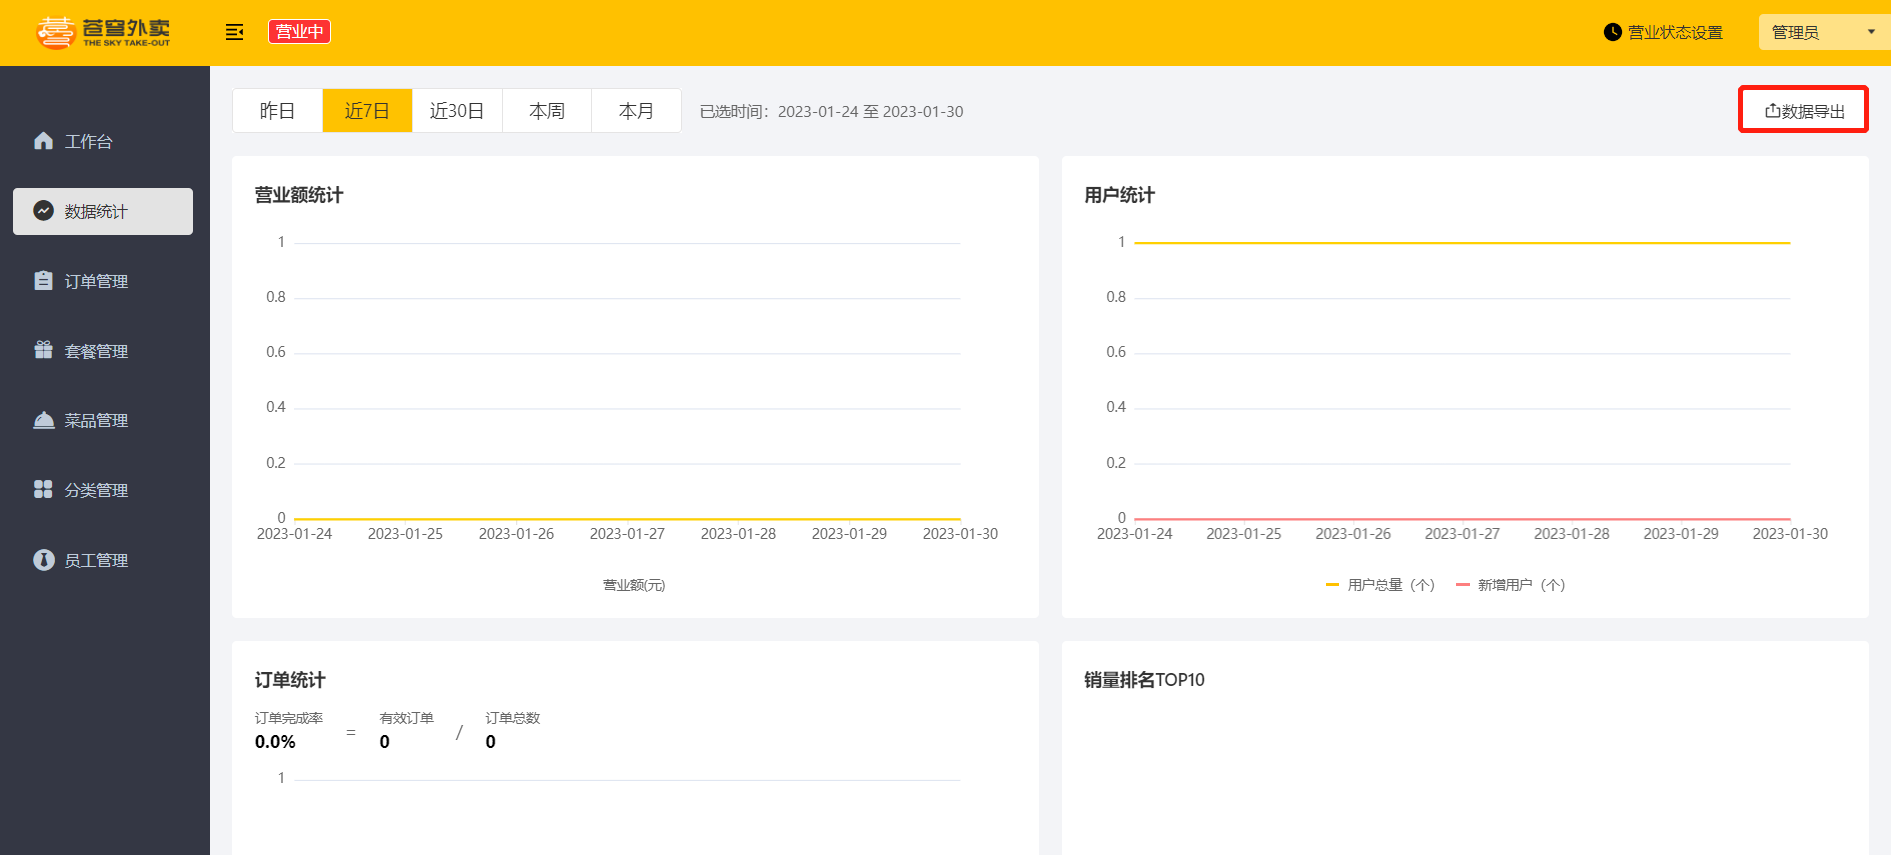 

**点击数据导出**：Excel报表下载成功

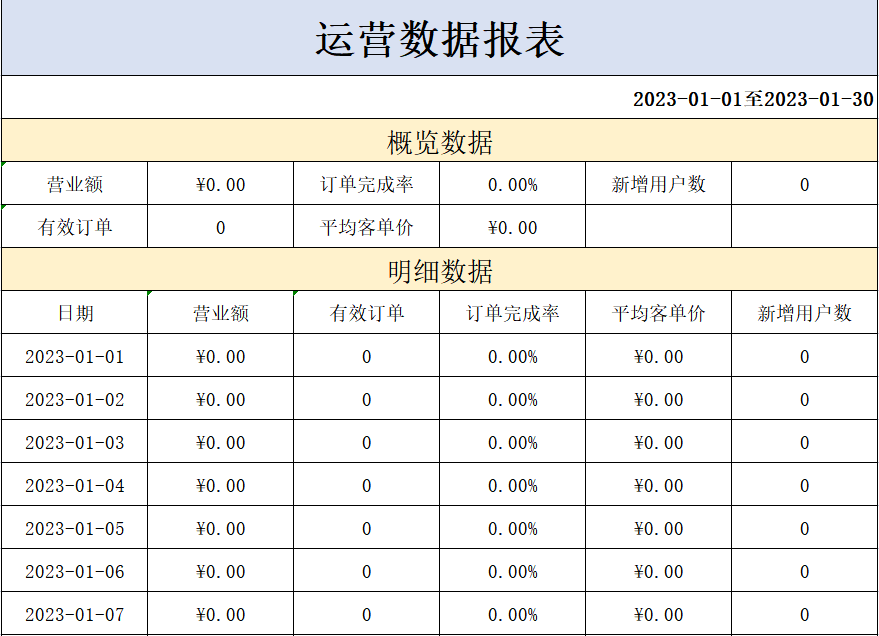


### Excel 导出验收矩阵（补充）

| 场景 | 预期 |
| --- | --- |
| 有30天运营数据 | 文件可打开，概览和30行明细均填充 |
| 某些日期无数据 | 对应行保留，数值为0 |
| 不包含今天的口径 | 标题、明细最后日期和接口说明一致 |
| 模板缺失或损坏 | 返回可识别错误并记录日志 |
| 文件名含中文 | 浏览器下载名称正确，不乱码 |
| 金额和百分比 | 单元格类型、精度和显示格式正确 |
| 无权限或超限请求 | 被拦截，不执行大查询 |
| 并发下载 | 内存、数据库和响应时间在限制内 |

下载后用 Excel 或兼容阅读器打开，检查公式、日期、百分比、列宽、空值和明细行数；HTTP 200 本身不能证明文件内容正确。


### 3.4 代码提交

> **PPT对照：** 课程提交页。

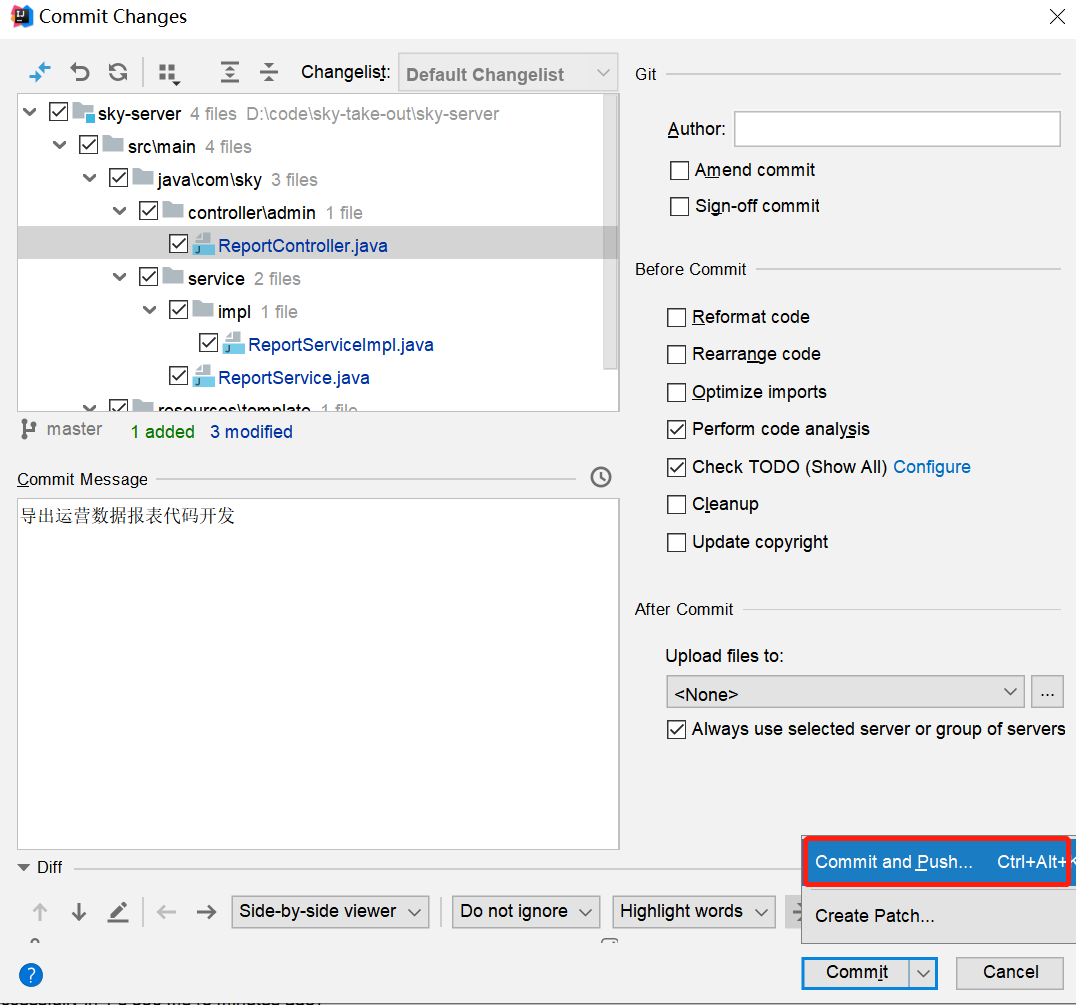 

后续步骤和其它功能代码提交一致，不再赘述。


### Excel 导出提交前检查（补充）

确认模板已纳入资源、日期范围和时区明确、响应头可下载、流能关闭、异常可观测、查询性能可接受，并移除固定本地路径和测试数据。


## 复习速查与本章验收（补充）

| 知识点 | 核心记忆 |
| --- | --- |
| 工作台 | 当天统一时间区间，指标口径和状态条件一致 |
| 金额 | 数据库 decimal 对应 BigDecimal，零分母返回0 |
| POI | Workbook、Sheet、Row、Cell 分层操作，资源用 try-with-resources |
| Excel读取 | 处理空行、空单元格、数字、日期、公式和边界 |
| 导出范围 | 最近30天是否含今天必须明确，并与模板标题一致 |
| 下载响应 | MIME、中文文件名、缓存和错误处理要完整 |
| 性能 | 工作台/导出按天循环可能造成 N+1 查询，需聚合或限制 |
| 模板 | 资源存在、Sheet和单元格位置可验证并有版本管理 |

### 跟练验收清单

- [ ] 工作台所有指标使用同一门店日期和时区。
- [ ] 订单总览有明确的当天上界，不统计未来订单。
- [ ] 营业额、客单价和百分比精度与前端契约一致。
- [ ] POI读写能安全处理空值、不同单元格类型和资源关闭。
- [ ] 导出模板存在且关键Sheet/单元格位置有检查。
- [ ] 最近30天范围、是否包含今天、明细行数和标题一致。
- [ ] 下载响应头、中文文件名、MIME和失败处理正确。
- [ ] 大范围或并发导出有性能、内存和权限限制。

### 自测问题

1. 工作台为什么要统一计算 begin 和 endExclusive？
2. 原订单总览缺少结束时间会统计到哪些数据？
3. 为什么金额不建议使用 Double？
4. POI读取时为什么不能无条件调用 getStringCellValue？
5. XSSFWorkbook 与 SXSSFWorkbook 的适用场景有什么差异？
6. 最近30天包含今天和不包含今天分别如何计算？
7. 下载接口为什么要设置 Content-Disposition 和 Excel MIME？
8. 模板资源缺失时为什么不能只打印堆栈？
9. 导出循环调用工作台服务会造成什么性能问题？
10. 百分比单元格写入0.25还是25由什么决定？

本章把管理端看板、Excel文件处理和运营报表下载串起来，验证时要同时看业务口径、数据库结果和最终文件。
